# Tomographic indexing notebook  
__Written by Haixing Fang, Jon Wright and James Ball__  
__Date: 21/02/2025__

Anri-based variant of the ImageD11 S3DXRD tomography workflow. Run these notebooks in order, each in a fresh kernel:

1. [tomo_1_index](tomo_1_index.ipynb): load experimental inputs, regenerate Anri indexing, refine/select measured-support seeds.
2. [tomo_2_map](tomo_2_map.ipynb): grain positions, sinograms and ASTRA EM_CUDA tomography.
3. [tomo_3_refinement](tomo_3_refinement.ipynb): diffraction origins and local voxel refinement, including Anri population starts.
4. [4_visualise](4_visualise.ipynb): refined maps, conditional split checks, TensorMap and MTEX exports.

Inputs are the experimental DataSet, segmented sparse pixels, measured peak tables, calibration/CIF and supplied manual mask. Only `/masks/<phase_str>` is read from the source grain file. No prior Anri fit or reconstructed map supplies orientations. JAX uses the available backend; ASTRA is needed by the later mapping notebook, not by Anri indexing.

Set `dset_path` to the experimental DataSet and choose a fresh `analysispath`, relative to that DataSet's folder or absolute. `None` uses its `anri_imaged11_s3dxrd` subfolder. Original inputs are retained. This experiment uses mm internally; beam widths, y0 and masks must use the same units as dty.

Follow the installed Anri skill: `histogram -> search -> filter -> fit -> localsearch -> populations`. All stages use the current `OPTIONS` automatically and record those settings when no manual `DECISION_NOTES` is supplied. To override defaults, update `OPTIONS[stage]` before its preview, for example `OPTIONS['search'].update(lit=1.5, etacut=0.15)`, then run the preview and stage. Manual notes are optional and do not set numerical parameters. Automatic records describe settings, not scientific validation. For a changed upstream stage, choose new output paths and remake every downstream stage; do not overwrite a source. A cheap first exploration can use a separate histogram with `gridstep=2` and fewer rings; this notebook's final manual-mask/ImageD11 handoff requires the native grid (`gridstep=1`).

Acquisition metadata comes from ImageD11's loaded `DataSet`, segmentation settings from `SegmenterOptions`, and calibration from `parameters.read_par_file(par_file)`. `EXPERIMENT_NOTES` is optional supplementary context, not a prerequisite. Review the beam/censor/absorption choices against the recorded settings; a motor setting alone does not establish calibration quality. If recalibration is needed, use `anri.calib rings`, write its pars, index through **fit only**, run `anri.calib fit` on that fit (never a local-search file), write calibrated pars and restart indexing in a new run folder. Do not assume a smooth microstructure or one population per voxel.

Inspect the machine before proceeding. `ESTIMATED_MINUTES` is optional runtime-planning information. For batch execution after the choices are known, wrap papermill in `timeout`, pin its CPU allocation with `taskset`, use `--execution-timeout` per cell, and enable `--log-output`. Stage logs are also saved in HDF5 and `anri_index.log`.

The native population map and the ImageD11 grain seeds are separate outputs. Global seeds below are still refined against measured peaks; they are not claims of measured local strain. Set the downstream notebooks' `dset_path` to the saved variant DataSet printed at the end of this notebook, including its run folder. They load that path directly and retain the DataSet's saved output paths.

In [ ]:
# this cell is tagged with parameters
from esrf_pathlib import ESRFPath as Path
import os, sys, importlib.metadata
# ImageD11 checkout selection follows the S3DXRD notebooks.
IMAGED11_PATH = '/home/esrf/charles27/Code/ImageD11'  # checkout folder within CHECKOUT_PATH
ANRI_PATH = '/home/esrf/charles27/Code/anri'
CHECKOUT_PATH = None  # None means guess the checkout parent folder

phase_str = 'Fe'

par_file = '/data/visitor/ma7056/id11/20260624/PROCESSED_DATA/pureIron_2_heating_3/pars_mm.json'
anri_output_path = None  # None: <ds.analysispath>/anri
cif_file = '/data/id11/archive/file_cif/Fe.cif'
THREADS = 48
SEED_FRACTIONS = (0.993, 0.999, 0.9999)
ACTIVE_FRACTION = 0.999
LOCAL_POPULATION_MIN = 0.1
# Optional supplementary notes and runtime estimate; metadata is loaded by ImageD11.
EXPERIMENT_NOTES = ''
ESTIMATED_MINUTES = None
# Optional examples (replace placeholders with your actual information):
# EXPERIMENT_NOTES = 'Calibration: <file/date>; additional operator context: <notes>.'
# ESTIMATED_MINUTES = 60  # example only; use your own runtime estimate
# Stage notes are optional: empty entries automatically record the effective OPTIONS.
# To add manual notes, replace example placeholders and uncomment the assignment.
# Override numerical defaults with OPTIONS[stage].update(...) before that stage's preview.
# Do not rerun this parameter cell mid-workflow: it resets notes and OPTIONS.
DECISION_NOTES = dict(histogram='', search='', filter='', fit='', localsearch='', populations='')
# Each grid-deviance comparison costs about an orientation fit. Opt in after estimating it.
GRID_DEVIANCE_STEPS = ()
MAX_GRID_ORIENTATIONS = 8_000_000  # bound the grid preview; lower it for the first pass

# Standard S3DXRD input DataSet
dset_path = '/data/visitor/ma7056/id11/20260624/PROCESSED_DATA/pureIron_2_heating_3/pureIron_2_heating_3_sff_after_20min0/pureIron_2_heating_3_sff_after_20min0_dataset.h5'
# Optional separate output analysis directory for this indexing run
analysispath = 'anri_imaged11_s3dxrd_4'
# Optional overrides for relocated experimental inputs. Usually leave empty.
INPUT_PATHS = {}

# Peak filtration and assignment (same selected route as before)
min_frames_per_peak = 0
cf_strong_frac = ACTIVE_FRACTION
cf_strong_dsmax = 1.6711536763930663
cf_strong_dstol = 0.005
peak_assign_tol = 0.05
# Starting proposals, not validated choices. Change them after the corresponding diagnostics.
OPTIONS = {'histogram': {'dataset': 'sff_after_20min0',
               'dty_source': 'dataset',
               'frame_dty': True,
               'grid_pad': 0.0,
               'gridstep': 1,
               'monitor': 'fpico4',
               'phase': 'Fe',
               'ring_merge': 0.0001,
               'rings': 6,
               'tth_tol': None,
               'detector_mask': None,
               'saturation': None,
               'sample': 'pureIron_2_heating_3'},
 'search': {'etacut': 0.2, 'grid': 0.5, 'lit': 1.0, 'max_chance': 0.5},
 'filter': {'censor': 1.0, 'keep': 100000, 'min_lr': 25.0, 'prune': 'likelihood'},
 'fit': {'absorption': False,
         'y0': None,
         'beam': 0.0,
         'block_gb': 1.0,
         'cand': 64,
         'censor': 1.0,
         'coarse': 1,
         'mask': 'disc',
         'n_iter': 30,
         'pad': 0.0,
         'save_model': True},
 'localsearch': {'levels': 2, 'cover': 0.95, 'per_voxel': 8},
 'populations': {'min_frac': 0.1, 'occupied': 0.1}}


In [ ]:
for key in ('OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS'): os.environ[key]='1'
os.environ['NUMBA_NUM_THREADS']=str(THREADS)
os.environ.setdefault('XLA_PYTHON_CLIENT_PREALLOCATE','false')
os.environ.setdefault('XLA_PYTHON_CLIENT_MEM_FRACTION','0.30')
if hasattr(os, 'sched_getaffinity'):
    os.sched_setaffinity(0, set(sorted(os.sched_getaffinity(0))[:THREADS]))
if IMAGED11_PATH is not None:
    exec(open('/data/id11/nanoscope/install_ImageD11_from_git.py').read())
    PYTHONPATH = setup_ImageD11_from_git(CHECKOUT_PATH, IMAGED11_PATH)
else:
    import site
    PYTHONPATH = site.getsitepackages()[0]
    # Prefer the local checkout when running from it, as in S3DXRD.
    from pathlib import Path as LocalPath
    local_candidates = [LocalPath.cwd(), LocalPath.cwd() / 'ImageD11', *LocalPath.cwd().parents]
    for candidate in local_candidates:
        if (candidate / 'ImageD11' / 'nbGui' / 'anri' / 'tomo_1_index.ipynb').is_file():
            loaded = sys.modules.get('ImageD11')
            if loaded is not None and (getattr(loaded, '__file__', None) is None or LocalPath(loaded.__file__).resolve().parent != candidate / 'ImageD11'):
                raise RuntimeError('Restart this notebook kernel to use the modified ImageD11 checkout')
            sys.path.insert(0, str(candidate))
            PYTHONPATH = str(candidate)
            break
print(PYTHONPATH)
if ANRI_PATH is not None:
    sys.path.insert(0, str(ANRI_PATH))
import anri.utils
anri.utils.setup(n_cpu=1)  # before any JAX computation, including diagnostic imports
import ImageD11
import h5py, numpy as np
import ImageD11.sinograms.dataset as dataset
import numba
numba.set_num_threads(THREADS)
def log(message):
    text = time.strftime('%Y-%m-%dT%H:%M:%S%z ') + str(message)
    print(text, flush=True)
    with (RUN/'anri_index.log').open('a') as stream: stream.write(text+'\n')
def snapshot(fig,name):
    from IPython.display import display
    import matplotlib.pyplot as plt
    fig.savefig(RUN/(name+'.png'),dpi=120,bbox_inches='tight'); display(fig); plt.close(fig)

import time,hashlib,copy
def record_decision(stage):
    note = DECISION_NOTES.get(stage, '')
    if not note.strip() or note.startswith('Automatic settings: '):
        DECISION_NOTES[stage] = 'Automatic settings: ' + repr(OPTIONS[stage])
    log(stage + ' decision: ' + DECISION_NOTES[stage])
import ImageD11.indexing as indexing
import ImageD11.grain as grain_module
from ImageD11 import cImageD11
from ImageD11.peakselect import select_ring_peaks_by_intensity
import matplotlib.pyplot as plt
cImageD11.cimaged11_omp_set_num_threads(THREADS)



# Setting path via: 
sys.path.insert(0, /home/esrf/charles27/Code/ImageD11 )
# Running from: /home/esrf/charles27/Code/ImageD11/ImageD11/__init__.py
/home/esrf/charles27/Code/ImageD11


# Load data
## Dataset

In [ ]:
# Use ImageD11's saved paths and naming conventions.
ds = dataset.load(str(dset_path))
SOURCE_DATASET = Path(dset_path).absolute()
INPUT_PATHS = {key: Path(value).absolute() for key, value in INPUT_PATHS.items()}
SOURCE_SPARSE = INPUT_PATHS.get('sparsefile', Path(ds.sparsefile)).absolute()
SOURCE_GRAINS = Path(ds.grainsfile)
PARFILE = Path(par_file if par_file is not None else INPUT_PATHS.get('parfile', ds.parfile)).absolute()
if par_file is not None:
    ds.parfile = str(PARFILE)
NAME, SAMPLE, SCAN = ds.dsname, ds.sample, ds.dset
PHASE = phase_str
DATA = SOURCE_DATASET.parent
RUN = (SOURCE_DATASET.parent / (analysispath or 'anri_imaged11_s3dxrd')).absolute()
analysispath = str(RUN)
ANRI = (RUN / (anri_output_path or 'anri')).absolute()
VALIDATION = RUN/'validation'
VARIANT_DATASET = RUN/(NAME+'_dataset.h5')
assert not VARIANT_DATASET.exists(), 'Choose a fresh analysispath; the variant DataSet already exists'
assert not (RUN/'input_manifest.json').exists(), 'Do not overwrite an earlier run manifest'
ANRI_FIT = ANRI/(NAME+'_fit.h5')
ANRI_POP = ANRI/(NAME+'_populations.h5')
CIF = Path(cif_file).absolute()
print(ds)


dataroot = "/data/visitor/ma7056/id11/20260624/RAW_DATA/"
analysisroot = "/data/visitor/ma7056/id11/20260624/PROCESSED_DATA/"
sample = "pureIron_2_heating_3"
dset = "sff_after_20min0"
shape = ( 400, 720)
# scans 400 from 1.1::[0:720] to 1.1::[287291:288011]


In [ ]:
import subprocess, json, hashlib
import shutil
for command in (['free', '-g'], ['nvidia-smi']):
    if shutil.which(command[0]): subprocess.run(command, timeout=10, check=False)
from ImageD11 import parameters
from ImageD11.sinograms.lima_segmenter import SegmenterOptions
segmentation_options = {}
segmenter_options = SegmenterOptions()
try:
    segmenter_options.load(str(SOURCE_DATASET), '/lima_segmenter')
except (KeyError, OSError) as error:
    print('Segmentation settings unavailable:', error)
else:
    segmentation_options = {name: getattr(segmenter_options, name) for name in segmenter_options.jobnames}
print('Recorded segmentation settings:', segmentation_options)
masterfile = getattr(ds, 'masterfile', None)
acquisition_metadata = {name: getattr(ds, name, None) for name in
                        ('sample', 'dset', 'detector', 'omegamotor', 'dtymotor', 'scans', 'frames_per_scan')}
acquisition_metadata = {name: value.tolist() if isinstance(value, np.ndarray) else value
                        for name, value in acquisition_metadata.items()}
calibration = parameters.read_par_file(str(PARFILE), phase_name=phase_str).get_parameters()
print(ds)
print('Calibration file:', PARFILE)
print('Calibration parameters:', calibration)
for p in (SOURCE_DATASET,SOURCE_SPARSE,SOURCE_GRAINS,PARFILE,CIF):
    assert p.is_file(),p
for folder in (RUN, ANRI, VALIDATION):
    folder.mkdir(parents=True, exist_ok=True)
manifest={'inputs':{},'sources':{},'experiment_notes':EXPERIMENT_NOTES,'estimated_minutes':ESTIMATED_MINUTES,
          'masterfile': str(masterfile) if masterfile else None, 'acquisition_metadata': acquisition_metadata,
          'calibration': {key: str(value) for key, value in calibration.items()},
          'segmentation_options': {key: str(value) for key, value in segmentation_options.items()}}
input_files = [SOURCE_DATASET, SOURCE_SPARSE, PARFILE, CIF]
if PARFILE.suffix == '.json':
    schema = json.loads(PARFILE.read_text())
    for entry in [schema.get('geometry', {})] + list(schema.get('phases', {}).values()):
        if 'file' in entry: input_files.append((PARFILE.parent/entry['file']).absolute())
for path in input_files:
    digest=hashlib.sha256()
    with path.open('rb') as f:
        for block in iter(lambda:f.read(1<<20),b''): digest.update(block)
    manifest['inputs'][str(path)]=digest.hexdigest()
for name,repo in [('ImageD11',PYTHONPATH),('anri',ANRI_PATH)]:
    if repo is None:
        manifest['sources'][name]='installed package'
        continue
    revision=subprocess.run(['git','rev-parse','HEAD'],cwd=repo,text=True,capture_output=True)
    manifest['sources'][name]=revision.stdout.strip()
    patch=subprocess.run(['git','diff','HEAD'],cwd=repo,text=True,capture_output=True)
    (RUN/(name+'_source.patch')).write_text(patch.stdout)
(RUN/'input_manifest.json').write_text(json.dumps(manifest,indent=2))
print('Fresh output directory:',RUN)


               total        used        free      shared  buff/cache   available
Mem:             755         333         164           1         265         421
Swap:              0           0           0
Mon Nov  2 20:22:49 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L40S                    On  |   00000000:01:00.0 Off |                    0 |
| N/A   40C    P0        

In [ ]:
assert not VARIANT_DATASET.exists(),'Preserve variant outputs; choose a new run folder instead of overwriting'
original_omega=ds.omega.copy(); original_dty=ds.dty.copy()
readonly_names=('pksfile','col4dfile','sparsefile','parfile','e2dxfile','e2dyfile','detectorh5','splinefile','maskfile','bgfile','masterfile','datapath')
readonly={key:getattr(ds,key,None) for key in readonly_names}
assert set(INPUT_PATHS).issubset(readonly_names), 'INPUT_PATHS only overrides read-only experimental inputs'
readonly.update({key:str(value.resolve()) for key,value in INPUT_PATHS.items()})
readonly.update(parfile=str(PARFILE), sparsefile=str(SOURCE_SPARSE))
for value in INPUT_PATHS.values(): assert value.is_file(),value
if analysispath is not None:
    ds.analysispath=str(RUN)
    ds.dsfile=None
    ds.update_paths(force=True)
VARIANT_DATASET=Path(ds.dsfile)
for key,value in readonly.items():
    if value is not None: setattr(ds,key,str(value))
ds.phases=ds.get_phases_from_disk()
print('Phases:',ds.phases.unitcells)
ucell=ds.phases.unitcells[PHASE]
with h5py.File(SOURCE_GRAINS,'r') as h:
    manual=h['masks/'+phase_str][()]


# Accept binary masks stored as bool, integer, or floating-point 0/1.
if manual.ndim != 2 or not np.all((manual == 0) | (manual == 1)):
    raise ValueError('The sample mask must be a 2D binary array; got shape %s, dtype %s' % (manual.shape, manual.dtype))
manual = manual.astype(bool, copy=False)
print('Manual mask:', manual.shape, 'included pixels:', int(manual.sum()))
# Grid compatibility is checked against the actual Anri and ImageD11 reconstruction grids.
assert not Path(ds.grainsfile).exists()
with h5py.File(ds.grainsfile,'w') as h: h.create_group('masks').create_dataset(phase_str,data=manual)
ds.save(str(VARIANT_DATASET))
check=dataset.load(str(VARIANT_DATASET))
np.testing.assert_array_equal(check.omega,original_omega)
np.testing.assert_array_equal(check.dty,original_dty)
print('Original DataSet:',SOURCE_DATASET)
print('Variant DataSet:',VARIANT_DATASET)
print('Manual support:',int(manual.sum()),'voxels; y0:',ds.y0,'step:',ds.ystep)
print('Angular wrap policy:',ds.omega_wraps,'actual span:',float(np.ptp(ds.omega)))
for key in ('pksfile','col4dfile','sparsefile','grainsfile','refmanfile','refpeaksfile','refmapfile','refoutfile'): print(key,getattr(ds,key))

Phases: {'Fe': Fe | [ 2.86680029  2.86680029  2.86680029 90.         90.         90.        ] | 229}
Manual mask: (407, 407) included pixels: 48994
Original DataSet: /data/visitor/ma7056/id11/20260624/PROCESSED_DATA/pureIron_2_heating_3/pureIron_2_heating_3_sff_after_20min0/pureIron_2_heating_3_sff_after_20min0_dataset.h5
Variant DataSet: /data/visitor/ma7056/id11/20260624/PROCESSED_DATA/pureIron_2_heating_3/pureIron_2_heating_3_sff_after_20min0/anri_imaged11_s3dxrd_4/pureIron_2_heating_3_sff_after_20min0_dataset.h5
Manual support: 48994 voxels; y0: 10.607131875362574 step: 0.00200031746031746
Angular wrap policy: True actual span: 359.97335000000476
pksfile /data/visitor/ma7056/id11/20260624/PROCESSED_DATA/pureIron_2_heating_3/pureIron_2_heating_3_sff_after_20min0/pureIron_2_heating_3_sff_after_20min0_peaks_table.h5
col4dfile /data/visitor/ma7056/id11/20260624/PROCESSED_DATA/pureIron_2_heating_3/pureIron_2_heating_3_sff_after_20min0/pureIron_2_heating_3_sff_after_20min0_peaks_4d.h5
sp

In [ ]:
# Anri expects ImageD11's canonical <analysisroot>/<sample>/<dsname> layout.
# Use ESRFPath's experiment root when available; otherwise use the saved DataSet root.
ANRI_ANALYSISROOT=Path(getattr(SOURCE_DATASET,'processed_data_path',ds.analysisroot))
canonical=ANRI_ANALYSISROOT/SAMPLE/NAME/(NAME+'_dataset.h5')
if not canonical.is_file() or not canonical.samefile(SOURCE_DATASET) or INPUT_PATHS:
    # A relocated local copy may not have the ESRF directory layout. Make an input view only.
    import shutil
    ANRI_ANALYSISROOT=RUN/'input_layout'
    layout=ANRI_ANALYSISROOT/SAMPLE/NAME
    layout.mkdir(parents=True,exist_ok=True)
    input_dataset=layout/(NAME+'_dataset.h5')
    shutil.copy2(SOURCE_DATASET,input_dataset)
    with h5py.File(input_dataset,'r+') as h:
        for key,value in INPUT_PATHS.items(): h.attrs[key]=str(Path(value))
        h.attrs['parfile']=str(PARFILE)
        h.attrs['sparsefile']=str(SOURCE_SPARSE)
    sparse_link=layout/(NAME+'_sparse.h5')
    if not sparse_link.exists(): sparse_link.symlink_to(SOURCE_SPARSE)
manifest=json.loads((RUN/'input_manifest.json').read_text())
with h5py.File(SOURCE_GRAINS,'r') as h: mask=h['masks/'+phase_str][()]
manifest['manual_mask_sha256']=hashlib.sha256(np.ascontiguousarray(mask).tobytes()).hexdigest()
manifest['manual_mask_source_file']=str(SOURCE_GRAINS)
(RUN/'input_manifest.json').write_text(json.dumps(manifest,indent=2))
print('Anri analysis root:',ANRI_ANALYSISROOT)

Anri analysis root: /data/visitor/ma7056/id11/20260624/PROCESSED_DATA


## Parameters
Use the calibration specified by `par_file` in the parameter cell.

In [ ]:
assert Path(ds.parfile).resolve()==PARFILE.resolve()
print('Calibration:',ds.parfile)

Calibration: /data/visitor/ma7056/id11/20260624/PROCESSED_DATA/pureIron_2_heating_3/pars_mm.json


## Phases
If the parameter file was a json, we can access the unit cells via `ds.phases.unitcells`

In [ ]:
ds.phases = ds.get_phases_from_disk()
ds.phases.unitcells

{'Fe': Fe | [ 2.86680029  2.86680029  2.86680029 90.         90.         90.        ] | 229}

In [ ]:
ucell = ds.phases.unitcells[phase_str]
print(ucell)

Fe | [ 2.86680029  2.86680029  2.86680029 90.         90.         90.        ] | 229


## Peaks

In [ ]:
cf_4d = ds.get_cf_4d()
ds.update_colfile_pars(cf_4d, phase_name=PHASE)
if not os.path.exists(ds.col4dfile):
    # save the 4D peaks to file so we don't have to spatially correct them again
    ImageD11.columnfile.colfile_to_hdf(cf_4d, ds.col4dfile)

Loading existing colfile from /data/visitor/ma7056/id11/20260624/PROCESSED_DATA/pureIron_2_heating_3/pureIron_2_heating_3_sff_after_20min0/pureIron_2_heating_3_sff_after_20min0_peaks_4d.h5
Reading your columnfile in hdf format


In [ ]:
# Optionally remove some noisy peaks
if min_frames_per_peak > 0:
    cf_4d.filter(cf_4d['npk2d'] > min_frames_per_peak)

# Visualise data
### $d^{*}$ vs $\eta$

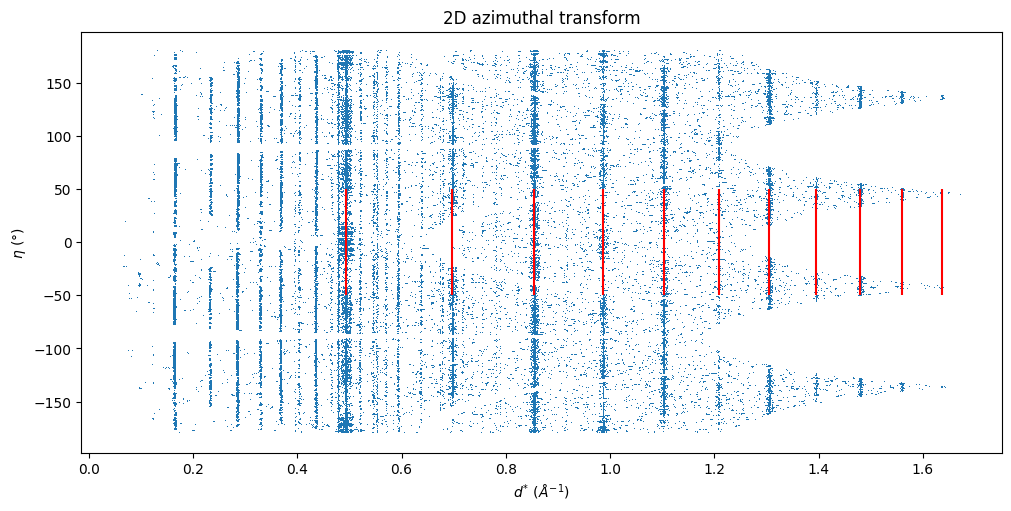

In [ ]:
skip = 1  # we can skip peaks to speed up plotting if needed
ucell.makerings(cf_4d.ds.max())
fig, ax = plt.subplots(figsize=(10,5), layout='constrained')
ax.plot(cf_4d.ds[::skip], cf_4d.eta[::skip], ',')
ax.vlines(ucell.ringds, -50, 50, color='red')
ax.set(xlabel=r'$d^{*}~(\AA^{-1})$', ylabel=r'$\eta~(\degree)$', title='2D azimuthal transform')
plt.show()

### Sinogram

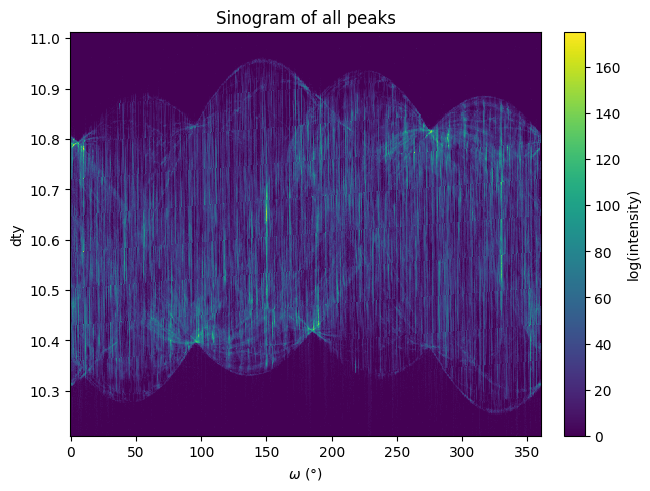

In [ ]:
fig, ax = plt.subplots(layout='constrained')
im, om_edges, dty_edges = ds.sinohist(np.log(ds.pk2d['sum_intensity']), ds.pk2d['omega'], ds.pk2d['dty'], return_edges=True)
pcm = ax.pcolormesh(om_edges, dty_edges, im.T)
ax.set(xlabel=r'$\omega~(\degree)$', ylabel='dty', title='Sinogram of all peaks')
cax = fig.colorbar(pcm, ax=ax, label='log(intensity)')
plt.show()

# Filtration
Here we are filtering our peaks (`cf_4d`) to select only the strongest ones for indexing purposes only!  
We first filter the peaks in $d^{*}$ to keep only those close to the predicted peaks from the unit cell.  
We then sort our peaks by intensity, and take a certain intensity-weighted fraction of them.  
`dstol`: The tolerance in $d^{*}$ between a peak and a predicted reflection.  
`dsmax`: The maximum allowed peak $d^{*}$ value. Used to limit the number of rings given to the indexer - 6-8 rings max are normally sufficient.   
`frac`: The intensity fraction: `frac=0.9` keeps 90% of the peak intensity. We recommend that you choose a value close to the 'elbow' of the plot.

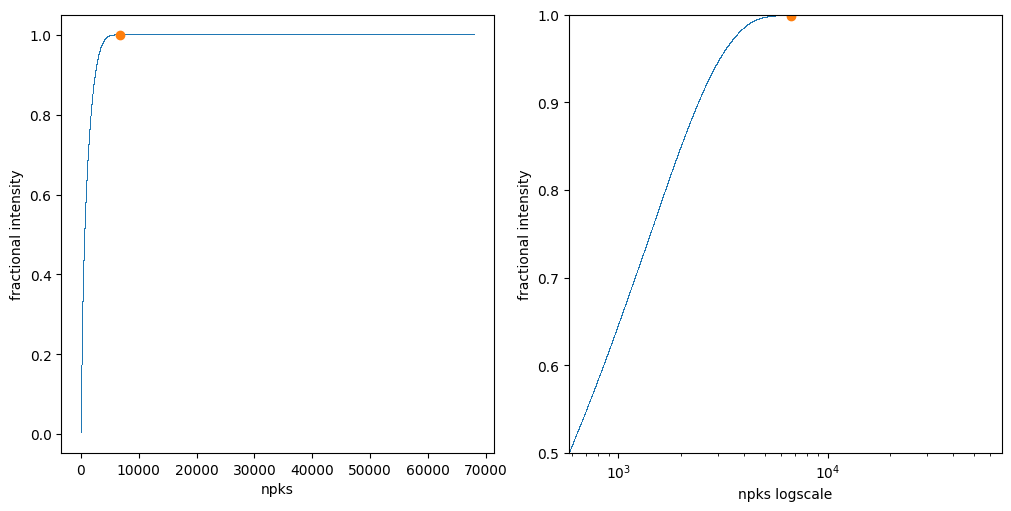

Filtered 6706 peaks from 152422


In [ ]:
cf_strong = select_ring_peaks_by_intensity(cf_4d, frac=cf_strong_frac, dsmax=cf_strong_dsmax, dstol=cf_strong_dstol, ucell=ucell, doplot=0.5)

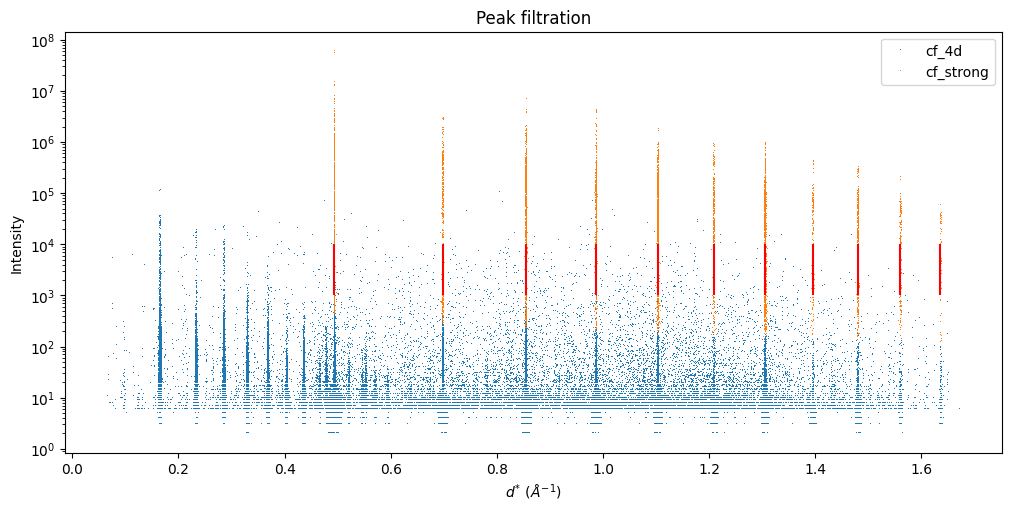

In [ ]:
skip = 1  # we can skip peaks to speed up plotting if needed
fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
ax.plot(cf_4d.ds[::skip], cf_4d.sum_intensity[::skip],',', label='cf_4d')
ax.plot(cf_strong.ds[::skip], cf_strong.sum_intensity[::skip],',', label='cf_strong')
ax.vlines(ucell.ringds, 1e3, 1e4, color='red')
ax.set(xlabel=r'$d^{*}~(\AA^{-1})$', ylabel='Intensity', yscale='log', title='Peak filtration')
ax.legend()
plt.show()

# Indexing
## Ring assignment

In [ ]:
indexer = ImageD11.indexing.indexer_from_colfile_and_ucell(cf_strong, ucell)
indexer.ds_tol = cf_strong_dstol
ImageD11.indexing.loglevel = 1
indexer.assigntorings()
ImageD11.indexing.loglevel = 3
print(f"Indexing {cf_strong.nrows} peaks")

info: gv: [[-0.3457686   0.75188684  0.21229692]
 [-0.08063362  0.34415968 -0.77771449]
 [ 0.36486734 -0.34533865  0.48406878]
 ...
 [-0.36565061  0.34383375 -0.48410405]
 [-0.41475816  0.68691358  0.29372307]
 [-0.37444923  0.36679433 -0.46010253]] (6706, 3) float64
info: Assign to rings, maximum d-spacing considered: 1.637900
info: Ring assignment array shape (6706,)
info: Ring     (  h,  k,  l) Mult  total indexed to_index  ubis  peaks_per_ubi   tth  ds
info: Ring 10  ( -2, -3, -3)   24     54       0       54     1     48  26.91  1.64
info: Ring 9   (  0, -2, -4)   24    154       0      154     3     48  25.63  1.56
info: Ring 8   ( -1, -1, -4)   36    431       0      431     5     72  24.30  1.48
info: Ring 7   (  0,  0, -4)    6    176       0      176    14     12  22.89  1.40
info: Ring 6   ( -1, -2, -3)   48   1252       0     1252    13     96  21.39  1.31
info: Ring 5   ( -2, -2, -2)    8    338       0      338    21     16  19.79  1.21
info: Ring 4   (  0, -1, -3)   24  

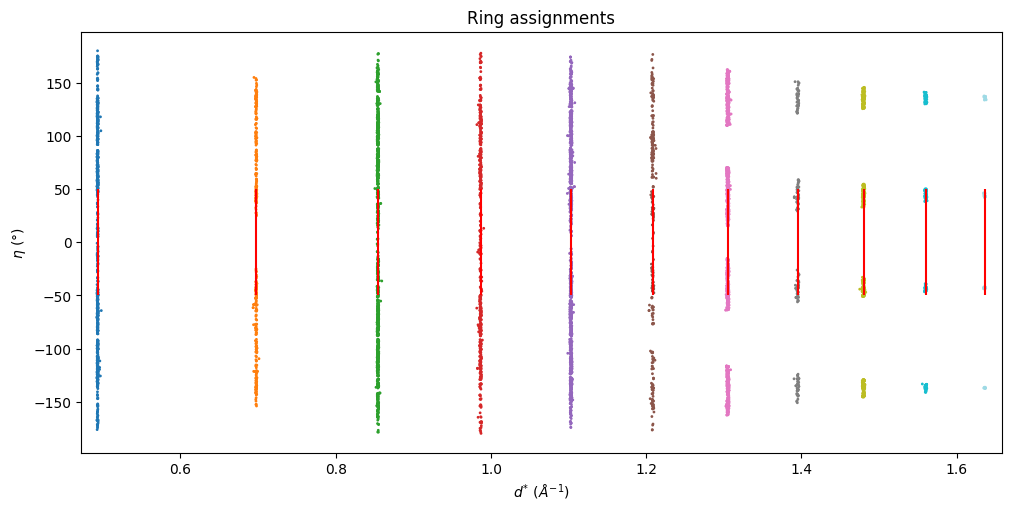

In [ ]:
skip = 1  # we can skip peaks to speed up plotting if needed
fig, ax = plt.subplots(layout='constrained', figsize=(10,5))
ax.scatter(indexer.colfile.ds[::skip], indexer.colfile.eta[::skip], c=indexer.ra[::skip]%20, cmap='tab20', s=1)
ax.vlines(ucell.ringds, -50, 50, color='red')
ax.set(xlabel=r'$d^{*}~(\AA^{-1})$', ylabel=r'$\eta~(\degree)$', xlim=(min(ucell.ringds[0], cf_strong.ds.min()) - 0.02, cf_strong.ds.max() + 0.02), title='Ring assignments')
plt.show()

## Anri orientation indexing

Generate orientations from the experimental sparse pixels using Anri's stages, diagnostics and plots, not notebook copies of its maths. Inspect a stage before choosing the next one's options. The final grain-seed refinement below still uses ImageD11 and is separate from the native Anri population result.

In [ ]:
import jax
import json
import anri.index.stages as stages
import anri.index.mask as masks
import anri.index.diagnostics as dg
import anri.index.plots as pl
import anri.index.populations as populations
from anri.index.search import GRID_STEPS, lit_map
from anri.io import provenance

OPTIONS['histogram'].update(analysisroot=str(ANRI_ANALYSISROOT),sample=SAMPLE,dataset=SCAN,parfile=str(PARFILE),cif=str(CIF),phase=PHASE)
paths={s:ANRI/f'{NAME}_{s}.h5' for s in stages.STAGES}
for path in paths.values(): assert not path.exists(),path
log('JAX devices: '+str(jax.devices()))
log('Experiment: '+EXPERIMENT_NOTES)
log('Estimated total run time (minutes): '+str(ESTIMATED_MINUTES))
print(OPTIONS)

2026-11-02T20:22:56+0100 JAX devices: [CudaDevice(id=0)]
2026-11-02T20:22:56+0100 Experiment: 
2026-11-02T20:22:56+0100 Estimated total run time (minutes): None
{'histogram': {'dataset': 'sff_after_20min0', 'dty_source': 'dataset', 'frame_dty': True, 'grid_pad': 0.0, 'gridstep': 1, 'monitor': 'fpico4', 'phase': 'Fe', 'ring_merge': 0.0001, 'rings': 6, 'tth_tol': None, 'detector_mask': None, 'saturation': None, 'sample': 'pureIron_2_heating_3', 'analysisroot': '/data/visitor/ma7056/id11/20260624/PROCESSED_DATA', 'parfile': '/data/visitor/ma7056/id11/20260624/PROCESSED_DATA/pureIron_2_heating_3/pars_mm.json', 'cif': '/data/id11/archive/file_cif/Fe.cif'}, 'search': {'etacut': 0.2, 'grid': 0.5, 'lit': 1.0, 'max_chance': 0.5}, 'filter': {'censor': 1.0, 'keep': 100000, 'min_lr': 25.0, 'prune': 'likelihood'}, 'fit': {'absorption': False, 'y0': None, 'beam': 0.0, 'block_gb': 1.0, 'cand': 64, 'censor': 1.0, 'coarse': 1, 'mask': 'disc', 'n_iter': 30, 'pad': 0.0, 'save_model': True}, 'localsearch'

## Histogram: preflight and ring choice

The dry run resolves paths and prints the histogram memory estimate without writing a stage. MLEM needs roughly four times that histogram memory; diagnostic plots also bring data/model arrays to host RAM. Check the machine output above before proceeding. The cake below samples the same scans as Anri's ring-width measurement. Pick clean, separated rings; inspect the full table, including unused neighbours. Fix a ring that wobbles with eta by calibration, not by widening `tth_tol`.

Record the ring/window numbers, segmentation cut versus `censor` (counts per histogram bin, not just per pixel), monitor and detector-mask choice in `DECISION_NOTES['histogram']`. If you change the selected rings or merge tolerance, rerun the preview before writing the histogram.

2026-11-02T20:22:57+0100 monitor fpico4: mean 2.594e+04, min / max 0.976 / 1.025 of the mean; intensities normalised to the mean
2026-11-02T20:22:57+0100 dataset /data/visitor/ma7056/id11/20260624/PROCESSED_DATA/pureIron_2_heating_3/pureIron_2_heating_3_sff_after_20min0/pureIron_2_heating_3_sff_after_20min0_dataset.h5; sparse pixels /data/visitor/ma7056/id11/20260624/PROCESSED_DATA/pureIron_2_heating_3/pureIron_2_heating_3_sff_after_20min0/pureIron_2_heating_3_sff_after_20min0_sparse.h5
2026-11-02T20:22:57+0100 pars    /data/visitor/ma7056/id11/20260624/PROCESSED_DATA/pureIron_2_heating_3/pars_mm.json: phase Fe, lattice 2.8668, 2.8668, 2.8668, 90, 90, 90, space group 229, 24 Laue-group rotations
2026-11-02T20:22:57+0100 geometry: wavelength 0.28442, distance 215.695; y0 (DataSet) 10.607131875362574; dty 10.213 + 400 x 0.00200032; omega -0.02673 .. 360 in 720 frames of 0.5
2026-11-02T20:22:57+0100 spatial correction: /data/visitor/ma7380/id11/20260901/PROCESSED_DATA/calib/e2dx_20250819.

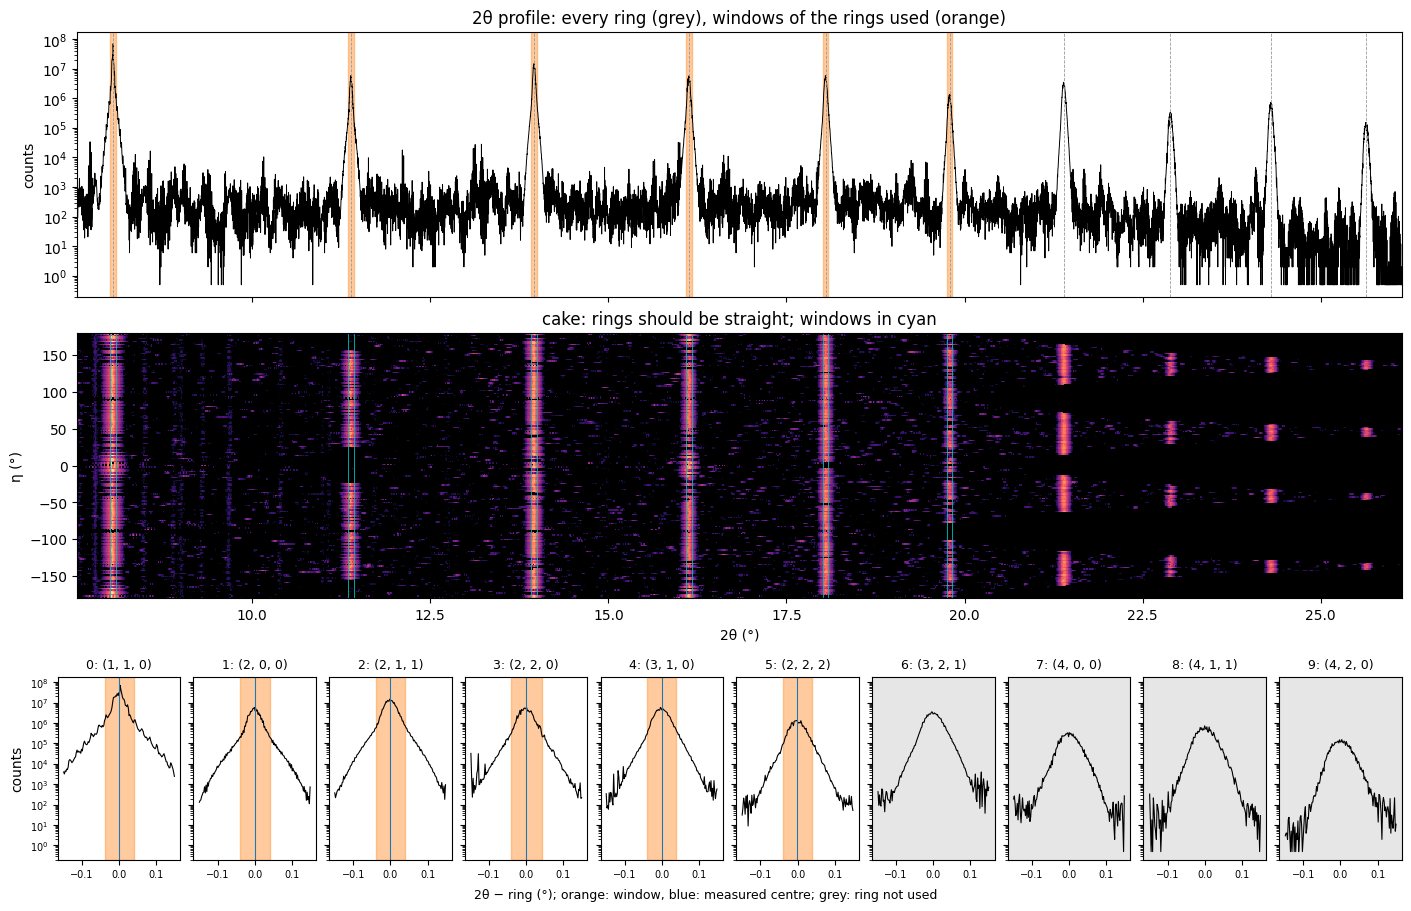

In [ ]:
stages.stage_histogram(check=True, log=log, **OPTIONS['histogram'])
open_keys = ('analysisroot', 'sample', 'dataset', 'phase', 'parfile', 'monitor', 'dty_source', 'gridstep', 'saturation', 'pol_factor')
preview = stages.open_dataset(**{key: value for key, value in OPTIONS['histogram'].items() if key in open_keys}, log=log)
rings_given = OPTIONS['histogram']['rings']
last_ring = rings_given if isinstance(rings_given, int) else max(rings_given)+1
cake = dg.ring_profile_cake(preview, n_rings=max(10, last_ring), cif=str(CIF), merge=OPTIONS['histogram']['ring_merge'])
fig = plt.figure(figsize=(14, 9), layout='constrained')
print(pl.plot_rings(fig, cake)(rings=rings_given, tth_tol=OPTIONS['histogram'].get('tth_tol')))
snapshot(fig, 'anri_rings')
histogram_preview = copy.deepcopy(OPTIONS['histogram'])
del preview, cake

In [ ]:
# Example: replace placeholders using the ring preview and recorded acquisition/segmentation settings.
# DECISION_NOTES['histogram'] = 'Rings <indices>: clean/separated because <observation>; tth_tol=<value or auto>, observed widths=<values>; ring_merge=<value>; monitor=<name>, flux variation=<value>; segmentation cut=<value>; detector mask=<file or none>; gridstep=1 for native-grid handoff.'
assert OPTIONS['histogram'] == histogram_preview, 'Histogram options changed: rerun the ring preview'
assert OPTIONS['histogram']['gridstep'] == 1, 'The final ImageD11/manual-mask handoff requires the native grid'
assert not paths['histogram'].exists(), 'Use a new output path for a histogram variant'
maskfile = paths['histogram'].with_name(paths['histogram'].stem+'_manual_'+PHASE+'_mask.npz')
assert not maskfile.exists(), 'Choose a new histogram/mask output path before starting the stage'
record_decision('histogram')
stages.stage_histogram(out=str(paths['histogram']),command='tomo_1_index.ipynb',log=log,**OPTIONS['histogram'])
d=stages.load_histogram(str(paths['histogram']))
assert manual.shape==(d['grid']['n'],d['grid']['n'])
masks.save_mask(str(maskfile),manual,d['grid']['step'])
np.testing.assert_array_equal(masks.load_mask(str(maskfile),d['grid']['n'],d['grid']['step']),manual)

2026-11-02T20:23:03+0100 histogram decision: Automatic settings: {'dataset': 'sff_after_20min0', 'dty_source': 'dataset', 'frame_dty': True, 'grid_pad': 0.0, 'gridstep': 1, 'monitor': 'fpico4', 'phase': 'Fe', 'ring_merge': 0.0001, 'rings': 6, 'tth_tol': None, 'detector_mask': None, 'saturation': None, 'sample': 'pureIron_2_heating_3', 'analysisroot': '/data/visitor/ma7056/id11/20260624/PROCESSED_DATA', 'parfile': '/data/visitor/ma7056/id11/20260624/PROCESSED_DATA/pureIron_2_heating_3/pars_mm.json', 'cif': '/data/id11/archive/file_cif/Fe.cif'}
2026-11-02T20:23:03+0100 monitor fpico4: mean 2.594e+04, min / max 0.976 / 1.025 of the mean; intensities normalised to the mean
2026-11-02T20:23:03+0100 dataset /data/visitor/ma7056/id11/20260624/PROCESSED_DATA/pureIron_2_heating_3/pureIron_2_heating_3_sff_after_20min0/pureIron_2_heating_3_sff_after_20min0_dataset.h5; sparse pixels /data/visitor/ma7056/id11/20260624/PROCESSED_DATA/pureIron_2_heating_3/pureIron_2_heating_3_sff_after_20min0/pureIro

## Histogram diagnostics: rows, y0 and manual support

Inspect flux steps and coverage before trusting the histogram. The edge estimate of y0 needs the whole sample in the scan; it is a diagnostic, not an automatic replacement for the saved Friedel-pair result. Set `OPTIONS['fit']['y0']` only after comparing the back-projections and manual outline. Leaving it `None` explicitly assumes the DataSet's value. If a changed y0 needs a different reconstruction grid, first regenerate the input DataSet/mask and histogram on that grid.

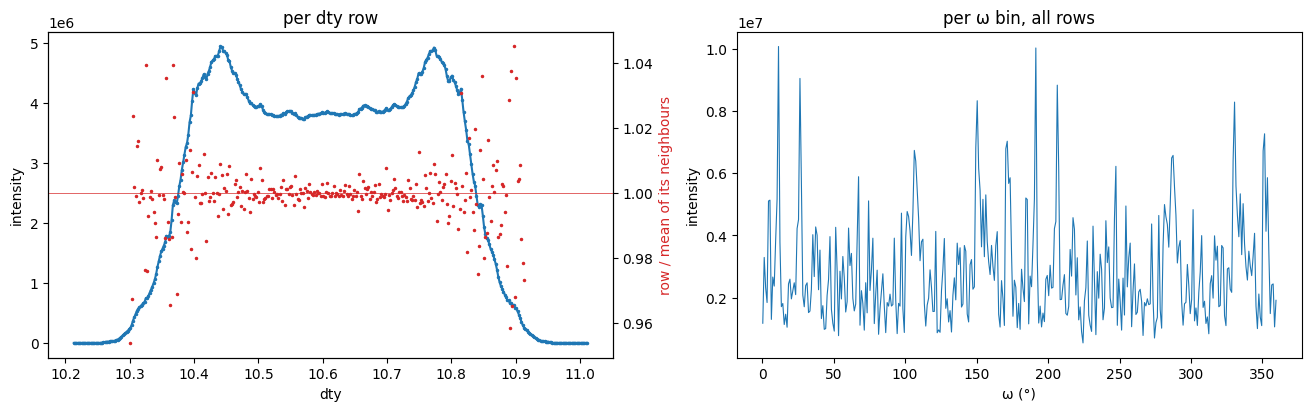

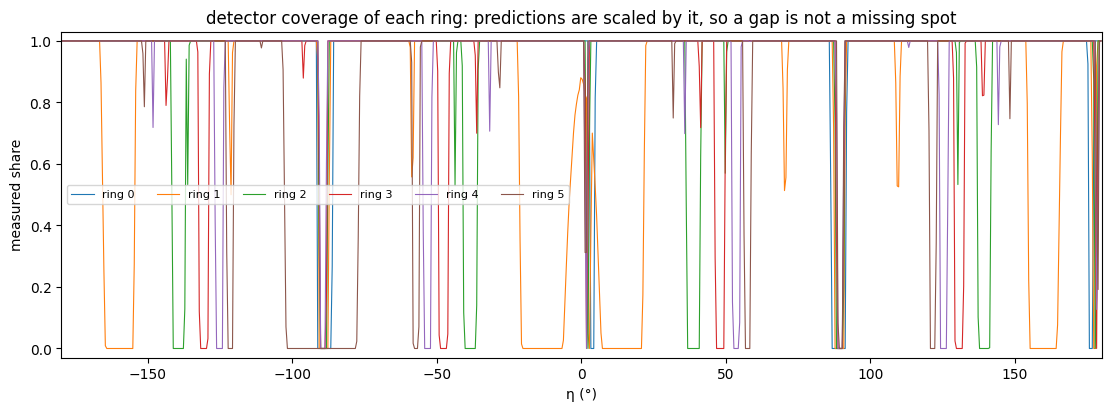

2026-11-02T20:23:18+0100 y0: edges=10.606125371780719, DataSet=10.607131875362574, fit proposal=10.607131875362574
2026-11-02T20:23:18+0100 End-row / brightest-row intensity: 0.0; above about 0.1 the sample may exceed the scan
y0 10.6071: from the sample's edges 10.6061, from the mean dty 10.6072


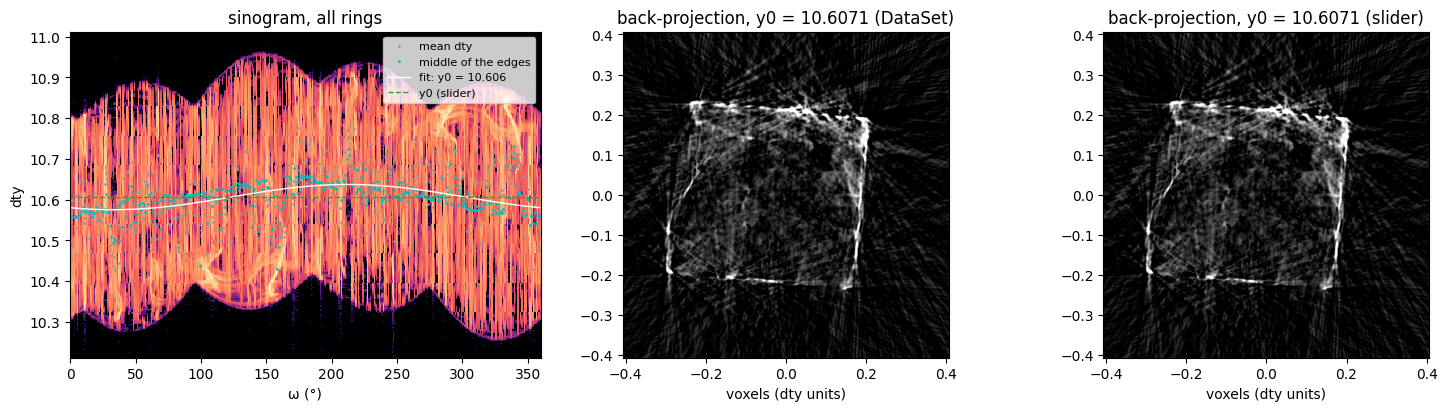

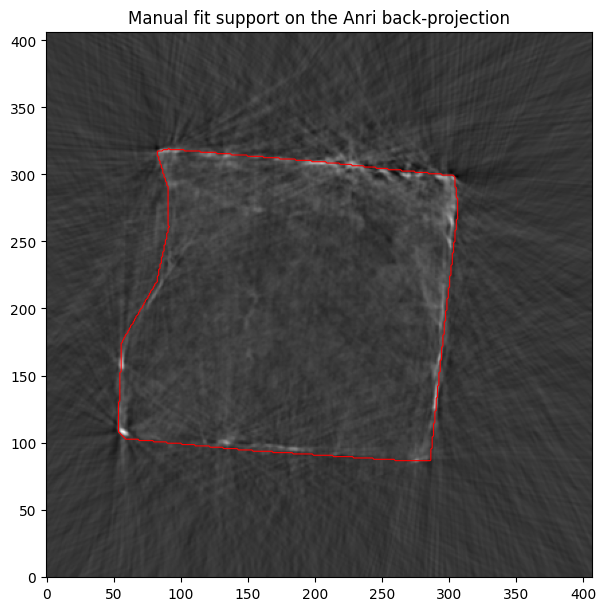

In [ ]:
rows = dg.row_profile(d['H'], d['n_rings'], d['scan'])
fig = plt.figure(figsize=(13, 4), layout='constrained')
pl.plot_rows(fig, rows)
snapshot(fig, 'anri_rows')
if 'coverage' in d['rings']:
    fig = plt.figure(figsize=(11, 4), layout='constrained')
    pl.plot_coverage(fig, d['rings']['coverage'], d['rings']['index'])
    snapshot(fig, 'anri_coverage')
edges = dg.y0_from_edges(d['H'], d['n_rings'], d['scan'])
y0_dataset = d['prov']['resolved'].get('y0_dataset')
fit_y0 = OPTIONS['fit']['y0'] if OPTIONS['fit']['y0'] is not None else y0_dataset
assert fit_y0 is not None, 'Choose y0 from the diagnostics; the DataSet has none'
log('y0: edges='+str(edges['y0'])+', DataSet='+str(y0_dataset)+', fit proposal='+str(fit_y0))
log('End-row / brightest-row intensity: '+str(edges['edge'])+'; above about 0.1 the sample may exceed the scan')
fig = plt.figure(figsize=(15, 4), layout='constrained')
print(pl.plot_y0(fig, edges, lambda value: dg.back_projection(d, value), y0_dataset if y0_dataset is not None else fit_y0, d['scan'])(y0=fit_y0))
snapshot(fig, 'anri_y0')
reconstruction = dg.back_projection(d, fit_y0)
fig, ax = plt.subplots(figsize=(6, 6), layout='constrained')
ax.imshow(reconstruction, origin='lower', cmap='gray')
ax.contour(manual.astype(float), levels=[0.5], colors='r', linewidths=0.8)
ax.set(title='Manual fit support on the Anri back-projection')
snapshot(fig, 'anri_manual_support')
geometry_preview = (d['prov']['id'], fit_y0)
del reconstruction

## Orientation search: lit cut, eta cut and grid

Put the lit cut near the area/intensity elbow, inspect the eta intensity that is excluded, and compare chance completeness against grid cost. The grid preview is bounded by `MAX_GRID_ORIENTATIONS`; a skipped grid has not been assessed. `GRID_DEVIANCE_STEPS` optionally compares full orientation fits: choose a finer grid only while its deviance improvement is supported by the data. Record these numbers in `DECISION_NOTES['search']`, then rerun the preview if you change the options.

lit 1: 1.34% of the bins, holding 99.9% of the intensity; per ring [3.74 0.54 1.55 0.79 1.07 0.34]%


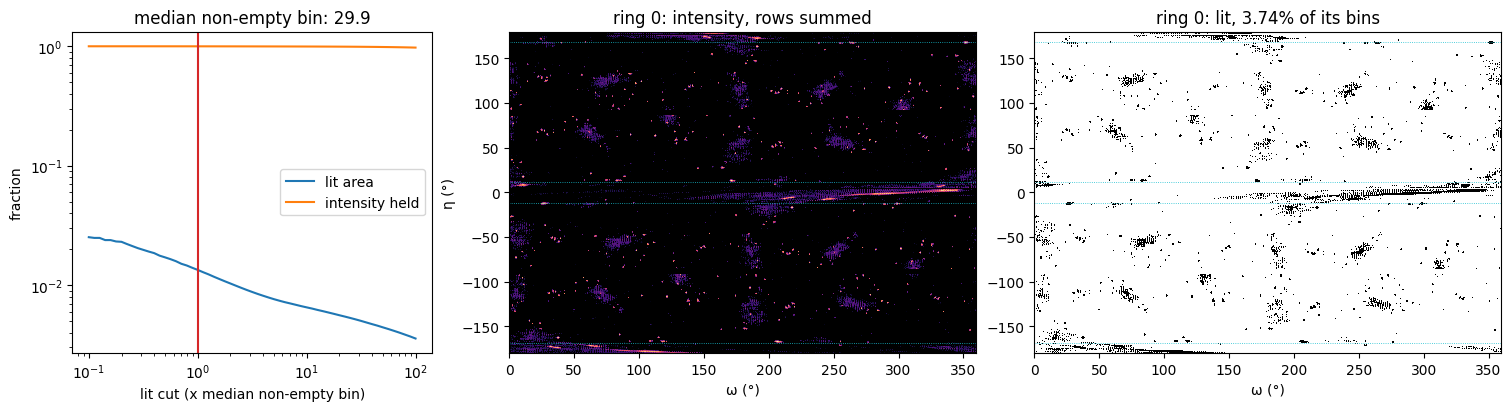

etacut 0.20: 12.8% of the reflections and 25.6% of the measured intensity not used; spots smeared up to 5.0 x in ω are kept


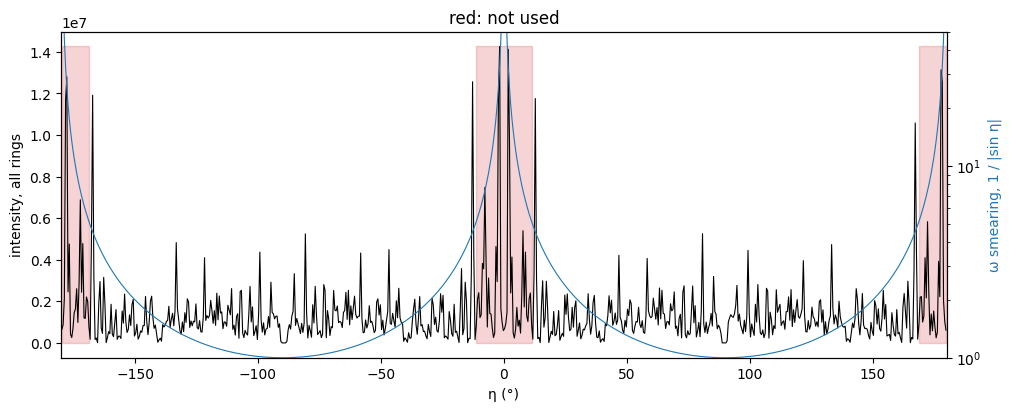

2026-11-02T20:23:37+0100 grid 3.0 deg: 31573 orientations, up to 2.60 deg from the truth; chance completeness 0.40
2026-11-02T20:23:38+0100 grid 2.5 deg: 52825 orientations, up to 2.17 deg from the truth; chance completeness 0.33
2026-11-02T20:23:39+0100 grid 2.0 deg: 106532 orientations, up to 1.73 deg from the truth; chance completeness 0.27
2026-11-02T20:23:39+0100 grid 1.5 deg: 252264 orientations, up to 1.30 deg from the truth; chance completeness 0.21
2026-11-02T20:23:40+0100 grid 1.0 deg: 829249 orientations, up to 0.87 deg from the truth; chance completeness 0.15
2026-11-02T20:23:41+0100 grid 0.5 deg: 6629484 orientations, up to 0.43 deg from the truth; chance completeness 0.09
grid step 0.5 deg


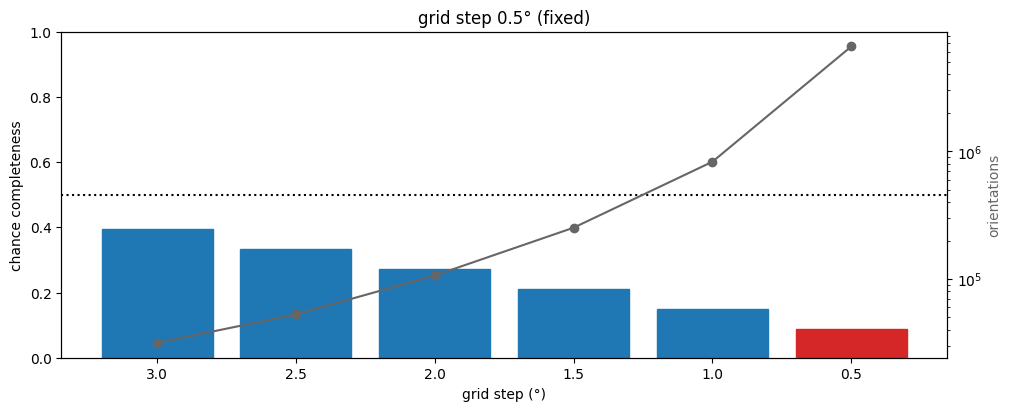

In [ ]:
d = stages.load_histogram(str(paths['histogram']))
fig = plt.figure(figsize=(15, 4), layout='constrained')
print(pl.plot_lit(fig, dg.lit_curve(d['H_lit'], d['n_rings'], d['scan']), d['scan'], OPTIONS['search']['etacut'])(lit=OPTIONS['search']['lit']))
snapshot(fig, 'anri_lit')
fig = plt.figure(figsize=(10, 4), layout='constrained')
print(pl.plot_etacut(fig, dg.eta_profile(d['H_lit'], d['n_rings'], d['scan']))(etacut=OPTIONS['search']['etacut']))
snapshot(fig, 'anri_etacut')
lit = lit_map(d['H_lit'], d['scan'], d['n_rings'], OPTIONS['search']['lit'], OPTIONS['search']['etacut'])
grid_steps = GRID_STEPS if OPTIONS['search']['grid'] is None else tuple(sorted(set(GRID_STEPS+(OPTIONS['search']['grid'],)), reverse=True))
chances = dg.grid_chances(d, lit, steps=grid_steps, max_orientations=MAX_GRID_ORIENTATIONS, log=log)
fig = plt.figure(figsize=(10, 4), layout='constrained')
print(pl.plot_grid(fig, chances, grid=OPTIONS['search']['grid'])(max_chance=OPTIONS['search']['max_chance']))
snapshot(fig, 'anri_grid')
preview_grid = OPTIONS['search']['grid']
if preview_grid is None: preview_grid = next((step for step, values in chances.items() if values[0] <= OPTIONS['search']['max_chance']), GRID_STEPS[-1])
assert preview_grid in chances, 'Grid preview exceeded its budget; choose a coarser grid or review resources before increasing the cap'
if GRID_DEVIANCE_STEPS:
    assert set(GRID_DEVIANCE_STEPS).issubset(chances), 'Preview the requested grid-deviance steps within the memory budget first'
    deviances = dg.grid_deviances(d, lit, tuple(GRID_DEVIANCE_STEPS), OPTIONS['search']['etacut'], min_lr=OPTIONS['filter']['min_lr'], keep=OPTIONS['filter']['keep'], censor=OPTIONS['filter']['censor'], log=log)
    fig = plt.figure(figsize=(12, 4), layout='constrained')
    pl.plot_grid_deviances(fig, deviances, OPTIONS['filter']['min_lr'])
    snapshot(fig, 'anri_grid_deviances')
search_preview = (d['prov']['id'], copy.deepcopy(OPTIONS['search']), MAX_GRID_ORIENTATIONS, tuple(GRID_DEVIANCE_STEPS))

In [ ]:
# Example: use the lit/eta plots and the successful bounded grid preview.
# DECISION_NOTES['search'] = 'lit=<value> at the elbow, retaining <fraction> of intensity; etacut=<value>, excluding <features/fraction>; grid=<degrees>, orientations=<count>, chance completeness=<value> versus max_chance=<value>; grid-deviance comparison=<result or not run>.'
DECISION_NOTES['search'] = 'lit 1; etacut .2'
assert search_preview == (provenance.read_provenance(str(paths['histogram']))['id'], OPTIONS['search'], MAX_GRID_ORIENTATIONS, tuple(GRID_DEVIANCE_STEPS)), 'Search source/options changed: rerun the successful preview'
assert not paths['search'].exists(), 'Use a new output path and remake downstream stages'
record_decision('search')
stages.stage_search(str(paths['histogram']),out=str(paths['search']),command='tomo_1_index.ipynb',log=log,**OPTIONS['search'])

2026-11-02T20:23:47+0100 search decision: lit 1; etacut .2
2026-11-02T20:23:53+0100 grid 0.5 deg: 6629484 orientations, up to 0.43 deg from the truth; completeness 3.1 s: median (chance) 0.09, 99th 0.31, max 1.00, halfway 0.54
2026-11-02T20:23:53+0100 -> /data/visitor/ma7056/id11/20260624/PROCESSED_DATA/pureIron_2_heating_3/pureIron_2_heating_3_sff_after_20min0/anri_imaged11_s3dxrd_4/anri/pureIron_2_heating_3_sff_after_20min0_search.h5


'/data/visitor/ma7056/id11/20260624/PROCESSED_DATA/pureIron_2_heating_3/pureIron_2_heating_3_sff_after_20min0/anri_imaged11_s3dxrd_4/anri/pureIron_2_heating_3_sff_after_20min0_search.h5'

## Likelihood selection

Choose `min_comp` relative to the search's measured chance level, not an arbitrary grain-completeness cutoff. After filtering, inspect likelihood against nearest-stronger misorientation. To change `min_lr`/`keep`, inspect `select_by_likelihood` on the saved ratios, then write a new filter variant and remake fit/local search/populations; do not overwrite this filter. Confirm `censor` against the segmentation cut times the pixel-frames a faint spot covers.

3293991 orientations above 0.09 go to the orientation fit


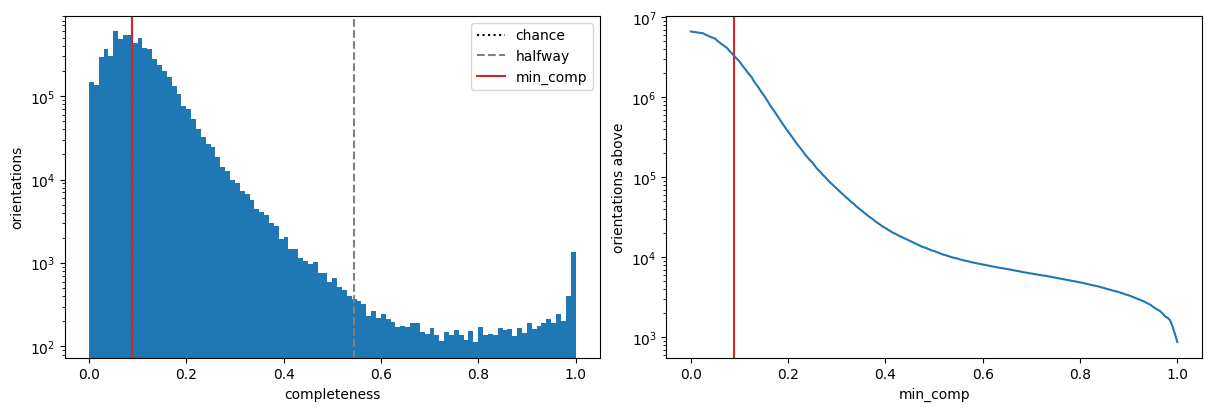

In [ ]:
search_prov = provenance.read_provenance(str(paths['search']))
with h5py.File(paths['search'], 'r') as h: completeness = h['completeness'][()]
chance = search_prov['results']['chance_completeness']
halfway = search_prov['results']['completeness_halfway']
min_comp = OPTIONS['filter'].get('min_comp')
if min_comp is None: min_comp = chance if OPTIONS['filter']['prune'] == 'likelihood' else halfway
fig = plt.figure(figsize=(12, 4), layout='constrained')
print(pl.plot_completeness(fig, completeness, chance, halfway, OPTIONS['filter']['keep'])(prune=OPTIONS['filter']['prune'], min_comp=min_comp))
snapshot(fig, 'anri_completeness')
filter_preview = (search_prov['id'], copy.deepcopy(OPTIONS['filter']))

2026-11-02T20:24:03+0100 filter decision: Automatic settings: {'censor': 1.0, 'keep': 100000, 'min_lr': 25.0, 'prune': 'likelihood'}
2026-11-02T20:24:12+0100   orientation MLEM 1 (SQUAREM step 1.0): deviance 4.52812e+10
2026-11-02T20:24:16+0100   orientation MLEM 2 (SQUAREM step 2.7, not taken): deviance 4.31592e+10
2026-11-02T20:24:19+0100   orientation MLEM 3 (SQUAREM step 3.4): deviance 4.28097e+10
2026-11-02T20:24:23+0100   orientation MLEM 4 (SQUAREM step 2.7, not taken): deviance 4.27029e+10
2026-11-02T20:24:26+0100   orientation MLEM 5 (SQUAREM step 7.9, not taken): deviance 4.26932e+10
2026-11-02T20:24:30+0100   orientation MLEM 6 (SQUAREM step 9.1, not taken): deviance 4.26901e+10
2026-11-02T20:24:33+0100   orientation MLEM 7 (SQUAREM step 10.0): deviance 4.26854e+10
2026-11-02T20:24:37+0100   orientation MLEM 8 (SQUAREM step 3.9): deviance 4.26833e+10
2026-11-02T20:24:40+0100   orientation MLEM 9 (SQUAREM step 4.4, not taken): deviance 4.26824e+10
2026-11-02T20:24:44+0100   o

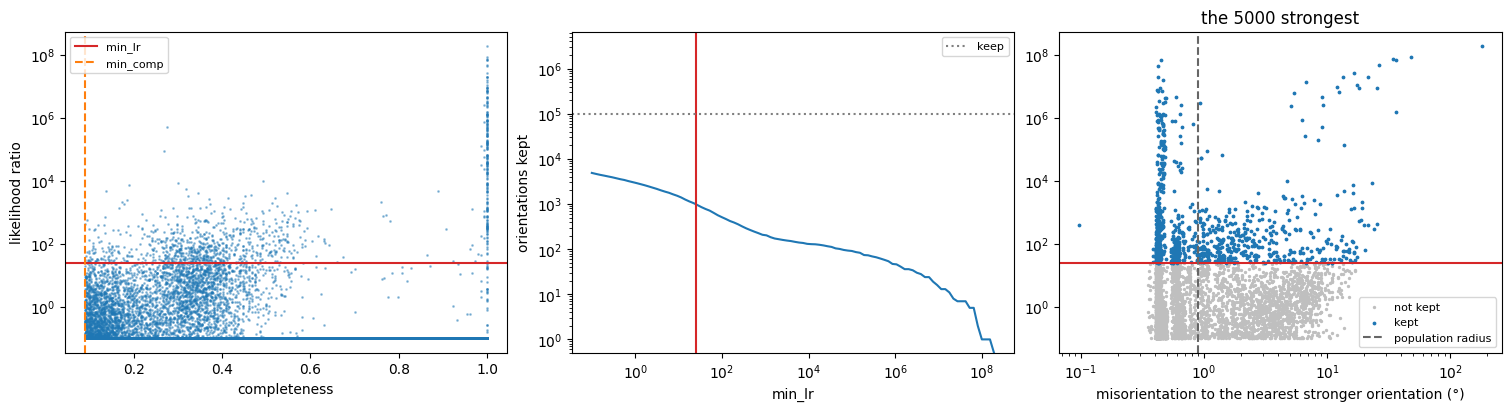

2026-11-02T20:25:30+0100 Orientations retained for occupancy fitting: 987


In [ ]:
# Example: use the completeness preview; the likelihood result is inspected after filtering.
# DECISION_NOTES['filter'] = 'prune=<method>; chance completeness=<value>, min_comp=<value or automatic rule>; min_lr=<value>, keep=<count>, chosen because <preview/previous diagnostic>; censor=<value> based on segmentation cut=<value> and typical pixel-frames=<value>; inspect retained likelihoods before fitting.'
assert filter_preview == (provenance.read_provenance(str(paths['search']))['id'], OPTIONS['filter']), 'Filter source/options changed: rerun the completeness preview'
assert not paths['filter'].exists(), 'Use a new filter output path'
record_decision('filter')
stages.stage_filter(str(paths['search']),out=str(paths['filter']),command='tomo_1_index.ipynb',log=log,**OPTIONS['filter'])
with h5py.File(paths['filter'], 'r') as h:
    n_orientations = len(h['U'])
    if 'likelihood_ratio' in h:
        fitted, lr = h['fitted'][()], h['likelihood_ratio'][()]
        assert len(lr), 'No fitted orientations; revisit rings, geometry, lit cut and completeness'
        with h5py.File(paths['search'], 'r') as search_file: U_grid = search_file['U_grid'][()]
        near = dg.nearest_stronger(U_grid[fitted], lr, d['ops'])
        fig = plt.figure(figsize=(15, 4), layout='constrained')
        print(pl.plot_likelihood(fig, fitted, lr, completeness[fitted], near, search_prov['resolved']['grid_step'], min_comp)(min_lr=OPTIONS['filter']['min_lr'], keep=OPTIONS['filter']['keep']))
        snapshot(fig, 'anri_likelihood')
        del U_grid, fitted, lr, near
log('Orientations retained for occupancy fitting: '+str(n_orientations))
assert n_orientations > 0, 'No orientations retained; inspect the selection before fitting'
filter_review_id = provenance.read_provenance(str(paths['filter']))['id']

## Native fit with exact manual support

Review the y0/mask overlay and likelihood plot first. Record in `DECISION_NOTES['fit']` the chosen y0, mask, candidates, iterations, beam FWHM/model, censor and absorption choice. `beam=0` assumes the two-row approximation to FWHM = dty step; it is not a measured beam width. Absorption is deliberately off in the starting proposals: justify that approximation, or supply `mu` in inverse **dty units**. A CIF-derived attenuation must use the same length units as this experiment. No spatial or orientation smoothing is introduced.

In [ ]:
# Example: use the y0/support overlay, selected likelihoods and recorded beam information.
# DECISION_NOTES['fit'] = 'y0=<value> <from DataSet or explicitly selected>, edge estimate=<value>; manual-mask overlap=<observation>; retained orientations=<count>, likelihood tail=<observation>; cand=<count>, n_iter=<count>; beam=<value> in dty units, <measured source or explicit approximation>; censor=<value>; absorption=<on/off> justified by <evidence/assumption>.'
assert provenance.read_provenance(str(paths['filter']))['id'] == filter_review_id, 'Selected filter changed: inspect its selection first'
assert provenance.read_provenance(provenance.upstream(str(paths['filter']), 'histogram'))['id'] == d['prov']['id'], 'Fit ancestry changed: reload its histogram and diagnostics'
assert not paths['fit'].exists(), 'Use a new fit output path'
assert OPTIONS['fit']['cand'] <= n_orientations, 'Fewer orientations survived than cand; choose cand explicitly'
OPTIONS['fit']['mask']=str(maskfile)
fit_y0 = OPTIONS['fit']['y0'] if OPTIONS['fit']['y0'] is not None else y0_dataset
assert fit_y0 is not None, 'Choose y0 before the fit'
assert geometry_preview == (d['prov']['id'], fit_y0), 'y0/source changed: rerun the geometry/mask preview'
assert masks.voxel_grid(d['scan'], fit_y0, OPTIONS['histogram']['grid_pad']) == d['grid']['n'], 'Chosen y0 changes the ImageD11 grid: regenerate the input mask and histogram first'
record_decision('fit')
log('y0 is '+('assumed from the input DataSet' if OPTIONS['fit']['y0'] is None else 'explicitly chosen')+': '+str(fit_y0))
log('Absorption: '+('enabled; verify attenuation units' if OPTIONS['fit']['absorption'] else 'not modelled (explicit notebook option)'))
log('Occupancy arrays, full grid: '+str(d['grid']['n']**2*OPTIONS['fit']['cand']*8/1e9)+' GB, plus histogram/model and fit workspaces')
callback,record=dg.convergence_recorder(OPTIONS['fit']['n_iter'],log=log)
stages.stage_fit(str(paths['filter']),out=str(paths['fit']),command='tomo_1_index.ipynb',log=log,callback=callback,**OPTIONS['fit'])
fit_record_id = provenance.read_provenance(str(paths['fit']))['id']
with h5py.File(paths['fit'],'r+') as h: h.create_dataset('diagnostic_deviance',data=record['deviance'])
ds.y0 = provenance.read_provenance(str(paths['fit']))['resolved']['y0']
ds.save(str(VARIANT_DATASET))  # downstream ImageD11 reconstruction must use the same axis

2026-11-02T20:25:56+0100 fit decision: Automatic settings: {'absorption': False, 'y0': None, 'beam': 0.0, 'block_gb': 1.0, 'cand': 64, 'censor': 1.0, 'coarse': 1, 'mask': '/data/visitor/ma7056/id11/20260624/PROCESSED_DATA/pureIron_2_heating_3/pureIron_2_heating_3_sff_after_20min0/anri_imaged11_s3dxrd_4/anri/pureIron_2_heating_3_sff_after_20min0_histogram_manual_Fe_mask.npz', 'n_iter': 30, 'pad': 0.0, 'save_model': True}
2026-11-02T20:25:56+0100 y0 is assumed from the input DataSet: 10.607131875362574
2026-11-02T20:25:56+0100 Absorption: not modelled (explicit notebook option)
2026-11-02T20:25:56+0100 Occupancy arrays, full grid: 0.084812288 GB, plus histogram/model and fit workspaces
2026-11-02T20:25:58+0100 y0 10.6071: voxels 407 x 407 of 0.00200032
2026-11-02T20:25:58+0100 mask (/data/visitor/ma7056/id11/20260624/PROCESSED_DATA/pureIron_2_heating_3/pureIron_2_heating_3_sff_after_20min0/anri_imaged11_s3dxrd_4/anri/pureIron_2_heating_3_sff_after_20min0_histogram_manual_Fe_mask.npz): 48

## Fit checks before local search

A flat deviance is not enough: inspect the occupancy still moving, the last candidates' shares, and measured/fitted intensity per row and ring. Steps between rows suggest a monitor problem; a smooth radial trend suggests the model or mask, not a reason to tune flux blindly. Compact positive residuals can be missed grains or another phase. Increase `cand` if the tail is appreciable, or iterations if thin features still move; write a new fit variant and remake later stages.

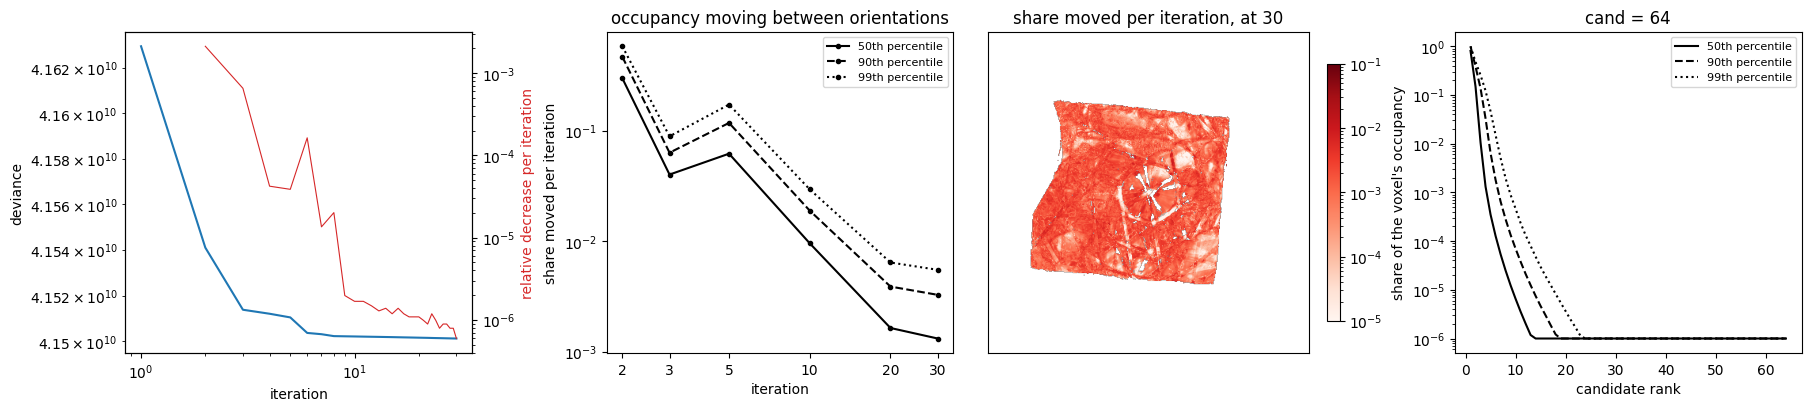

2026-11-02T20:26:48+0100 Last 8 candidate shares, median / 99th percentile: [1.22999941e-15 7.12225185e-12]
2026-11-02T20:26:48+0100 Measured/fitted row ratios, min / median / max: [0.88128126 1.00496364 1.47685933]
2026-11-02T20:26:48+0100 Fit summary: {'orientations': 987, 'row_ratio_rms': 0.17197982966899872, 'voxels_in_mask': 48994}


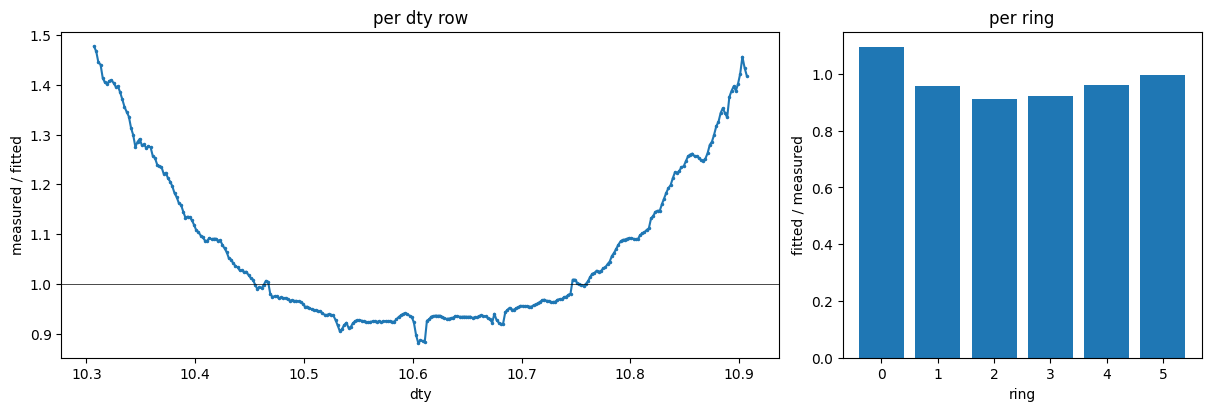

ring 0, eta 80..100 deg


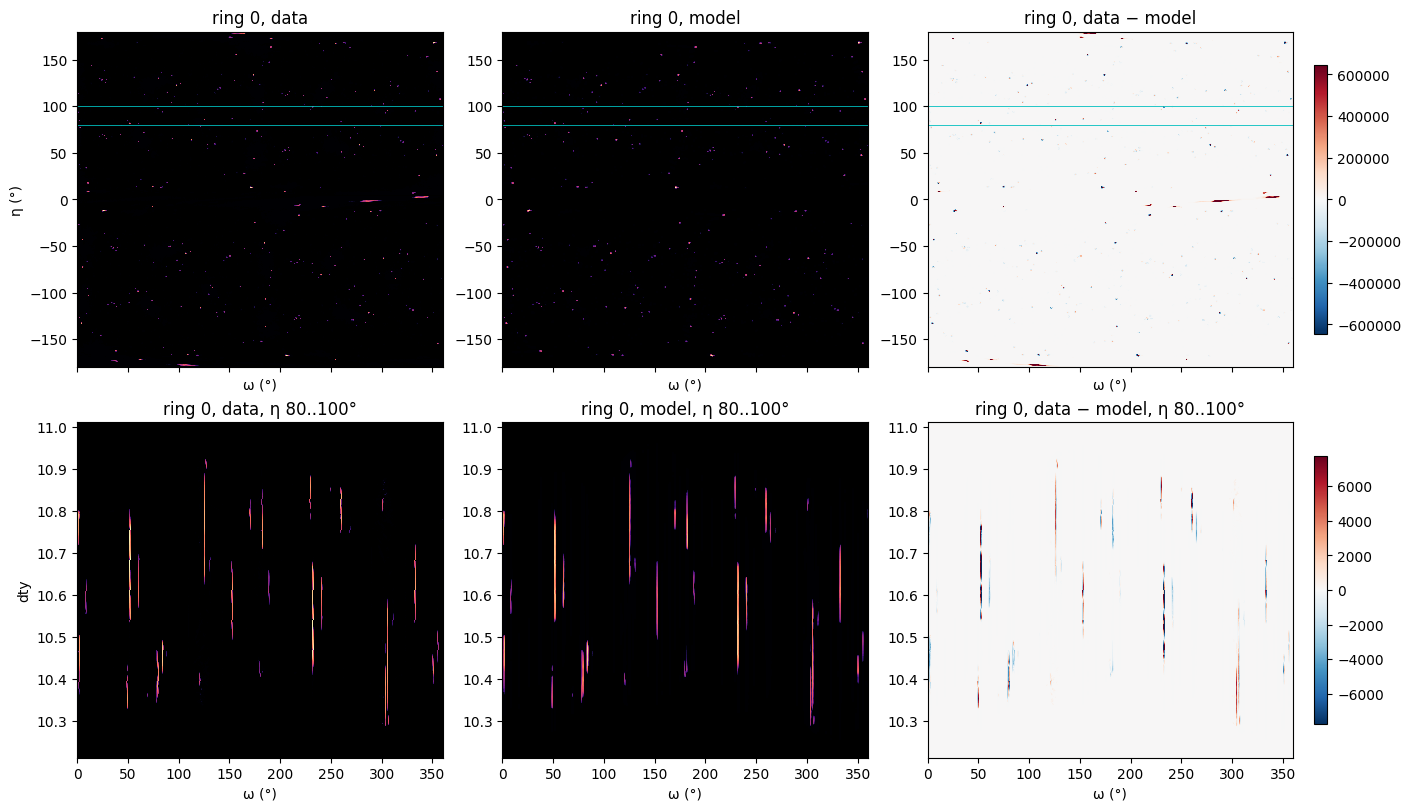

ring 1, eta 80..100 deg


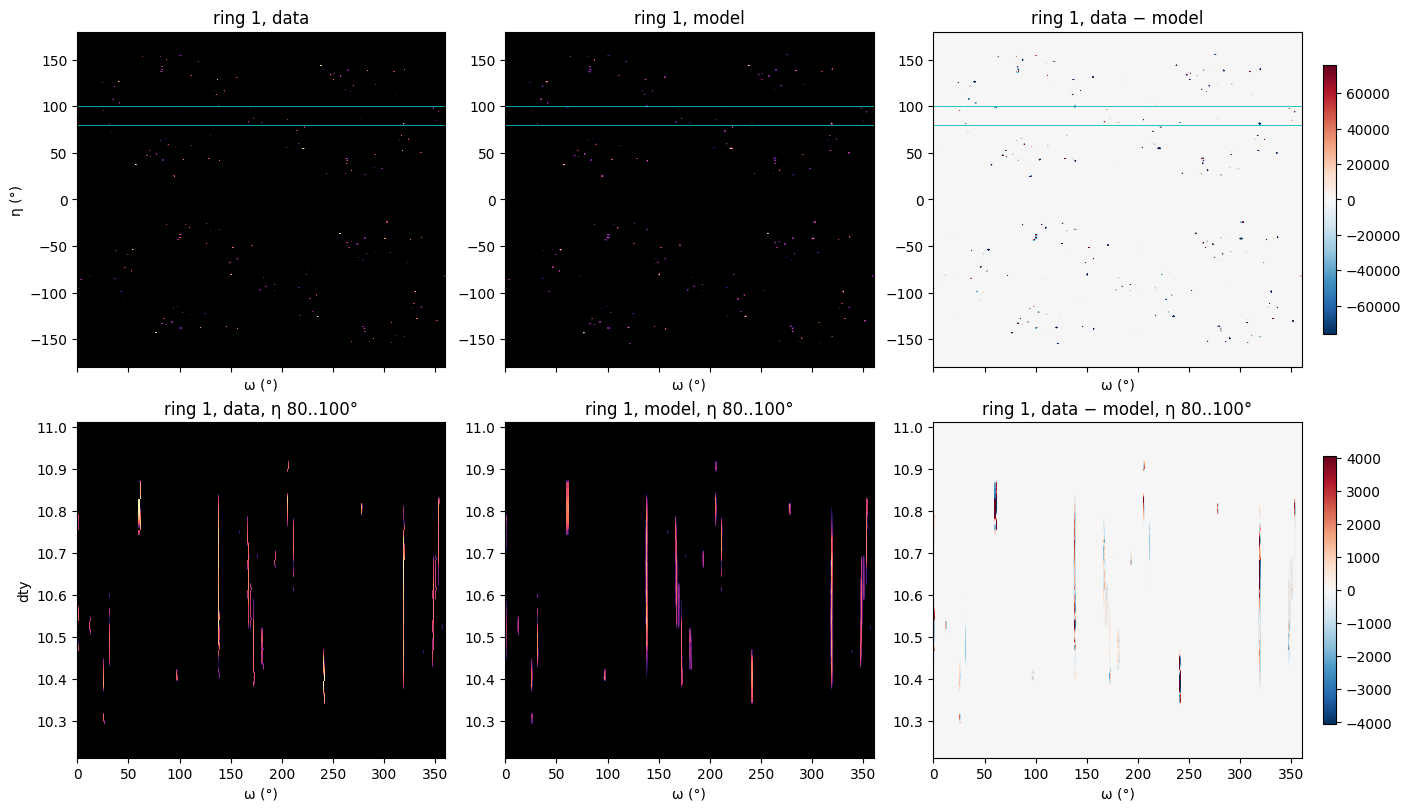

ring 2, eta 80..100 deg


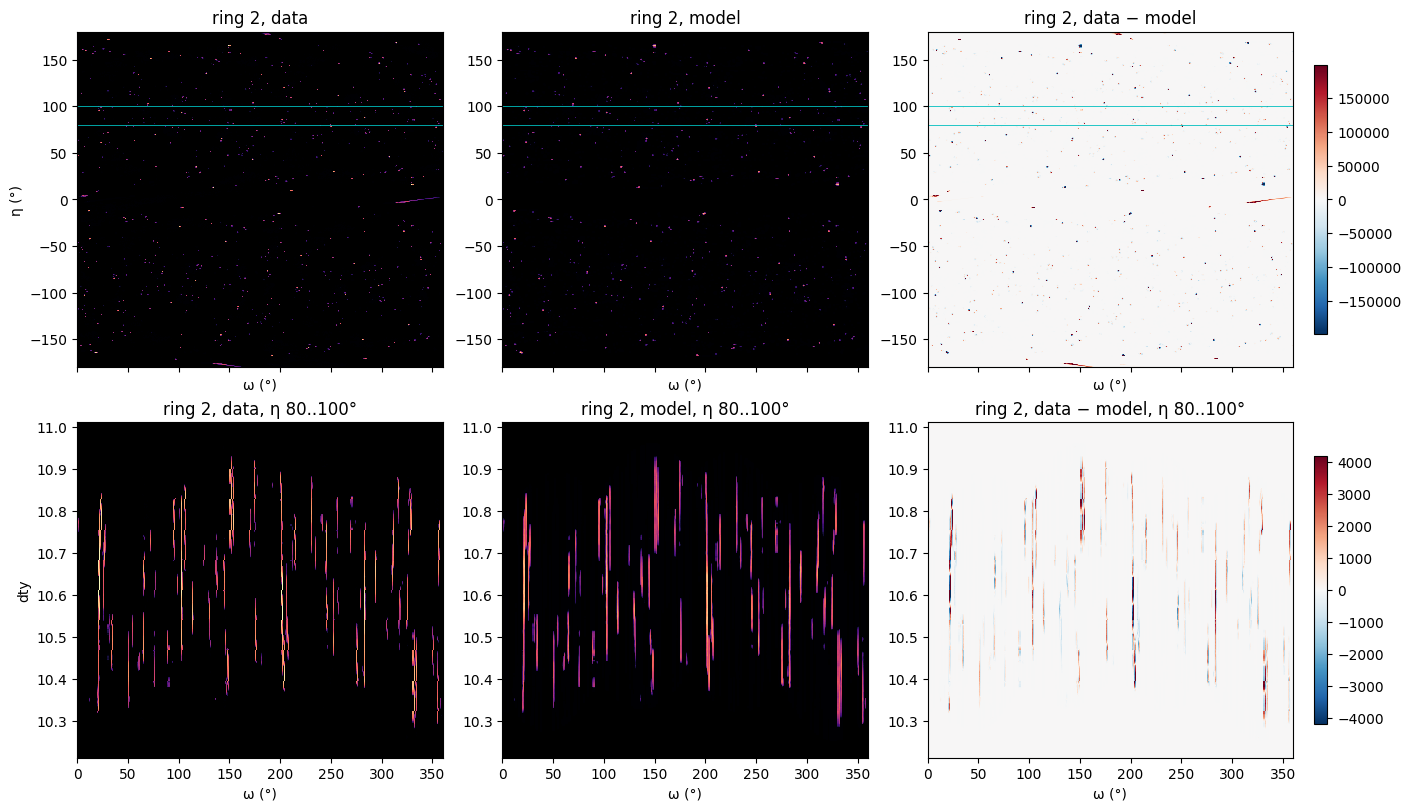

ring 3, eta 80..100 deg


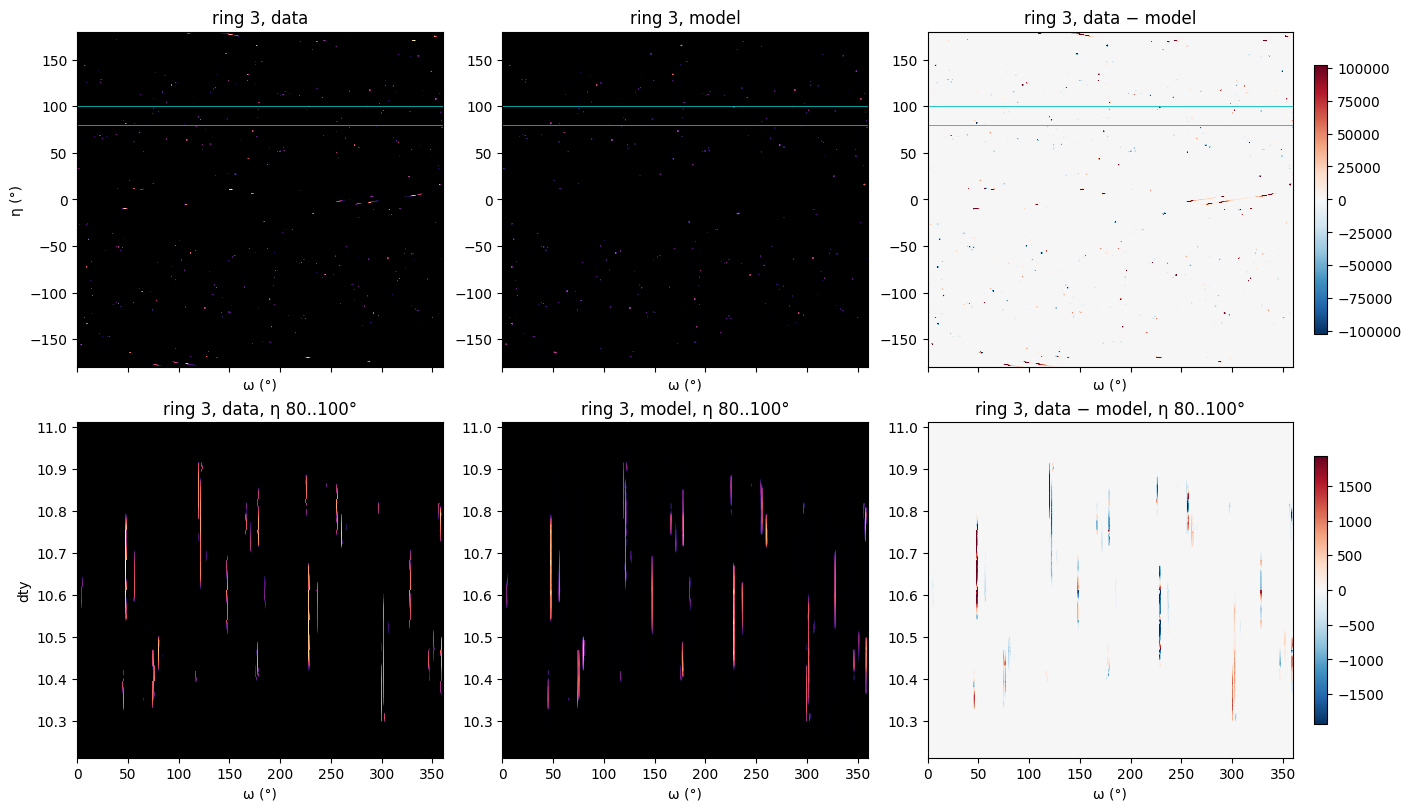

ring 4, eta 80..100 deg


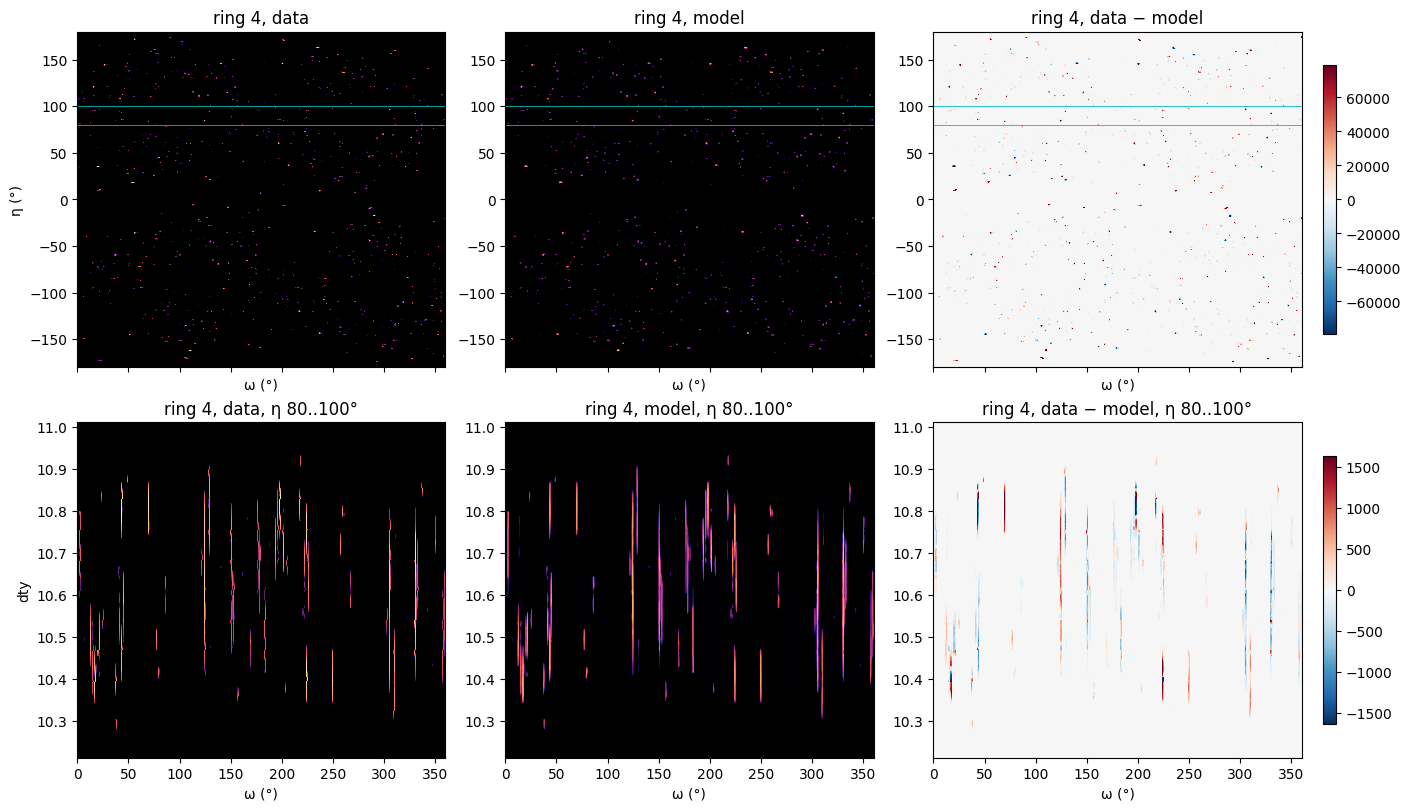

ring 5, eta 80..100 deg


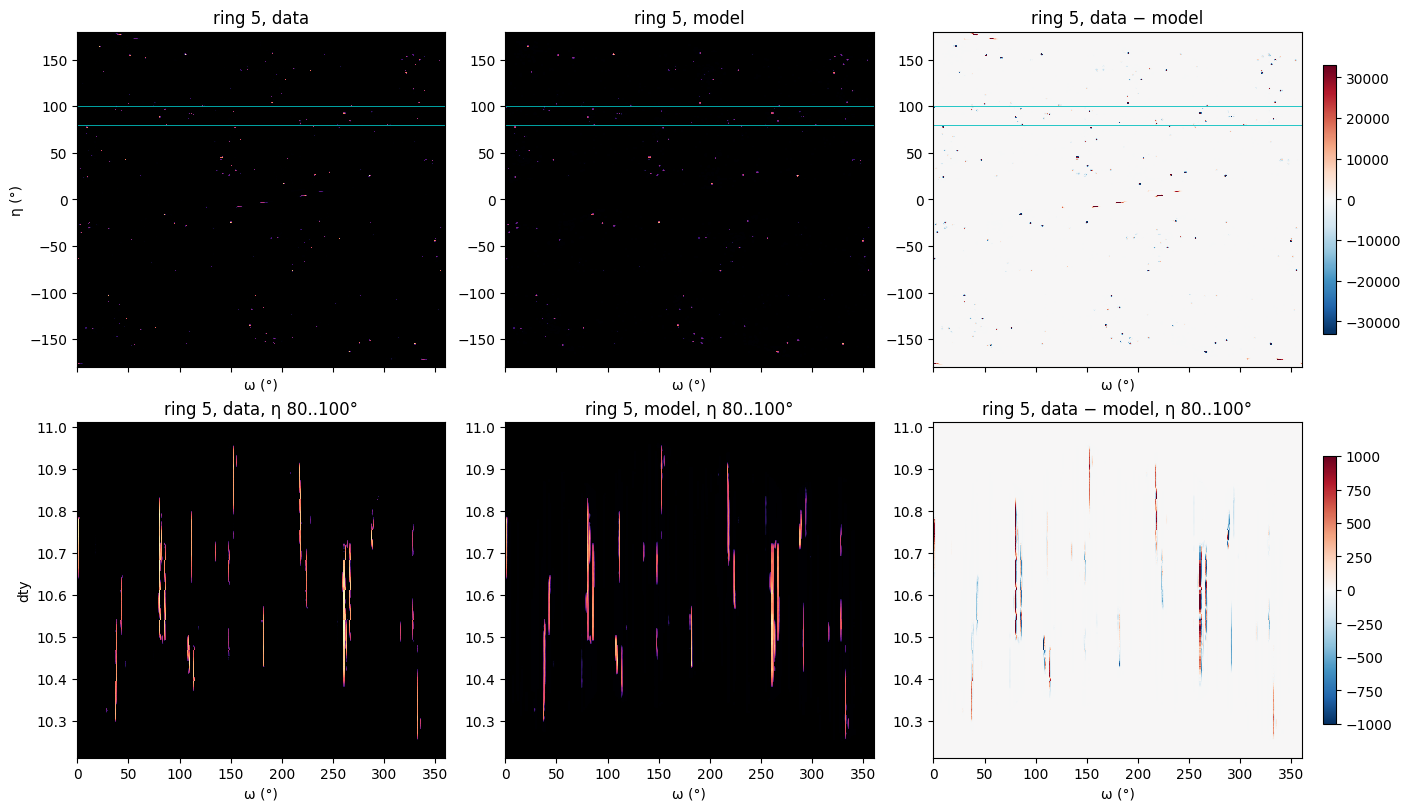

0.0% of occupied voxels need more than per_voxel = 8 orientations to hold 0.95 of their occupancy (median 2); level 1: 342 orientations used, 9234 children, at most 216 candidates per voxel (the fit had 64)


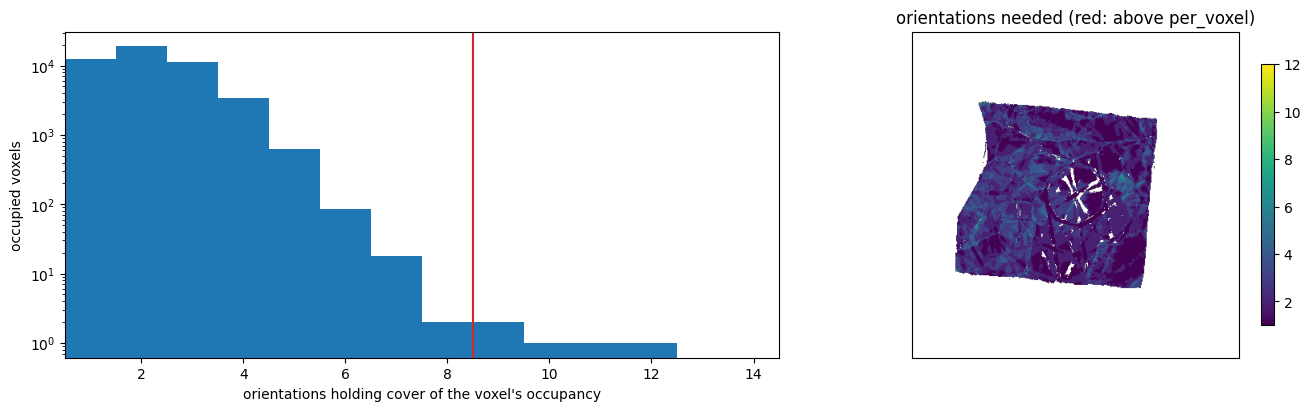

In [ ]:
assert provenance.read_provenance(str(paths['fit']))['id'] == fit_record_id, 'Convergence record belongs to another fit'
with h5py.File(paths['fit'], 'r') as h:
    f, cand, fitted_voxels = h['f'][()], h['cand'][()], h['mask'][()]
    row_ratio = h['row_ratio'][()]
    model = h['model'][()] if 'model' in h else None
nr = d['grid']['n']
total = f.sum(1)
occupied_voxels = populations.select_occupied(total, fitted_voxels, OPTIONS['populations']['occupied'])
assert occupied_voxels.any(), 'No occupied voxels at the proposed cut: inspect the fit and occupied option'
fig = plt.figure(figsize=(18, 4), layout='constrained')
pl.plot_convergence(fig, record, f, fitted_voxels, occupied_voxels, nr)
snapshot(fig, 'anri_convergence')
tail_count = max(1, f.shape[1]//8)
tail = dg.candidate_shares(f, occupied_voxels)[:, -tail_count:].sum(1)
log('Last '+str(tail_count)+' candidate shares, median / 99th percentile: '+str(np.percentile(tail, [50, 99])))
log('Measured/fitted row ratios, min / median / max: '+str(np.nanpercentile(row_ratio, [0, 50, 100])))
log('Fit summary: '+str(provenance.read_provenance(str(paths['fit']))['results']))
if model is not None:
    fig = plt.figure(figsize=(12, 4), layout='constrained')
    pl.plot_row_ratios(fig, rows['dty'], row_ratio, dg.ring_ratios(d['H'], model, d['n_rings'], d['scan'], search_prov['options']['etacut']))
    snapshot(fig, 'anri_fit_ratios')
    for ring in range(d['n_rings']):
        fig = plt.figure(figsize=(14, 8), layout='constrained')
        print(pl.plot_residual(fig, d['H'], model, d['n_rings'], d['scan'])(ring=ring, eta=(80, 100)))
        snapshot(fig, 'anri_residual_ring_'+str(ring))
    del model
fig = plt.figure(figsize=(13, 4), layout='constrained')
print(pl.plot_local_slots(fig, f, cand, fitted_voxels, occupied_voxels, nr)(cover=OPTIONS['localsearch']['cover'], per_voxel=OPTIONS['localsearch']['per_voxel']))
snapshot(fig, 'anri_local_slots')
local_search_preview = (fit_record_id, copy.deepcopy(OPTIONS['localsearch']))

## Local search

Choose `cover` and `per_voxel` from the slot map, not from an assumed number of grains per voxel. Each parent creates 27 candidates at each level; every level costs about one fit. Red over whole grains means the cap is too small. Record the fit-quality checks and the slot counts in `DECISION_NOTES['localsearch']`. Afterward inspect deviance by level and population shifts: grid-scale corrections are expected; larger changes need spatial/physical interpretation, not automatic smoothing.

In [ ]:
# Example: use convergence, row/ring residuals, candidate tails and the slot preview.
# DECISION_NOTES['localsearch'] = 'Deviance change=<value> over final <count> iterations; occupancy change=<observation>; candidate-tail median/99th percentile=<values>; row ratios=<range>, residual structure=<observation>; cover=<value>, per_voxel=<count>, levels=<count> chosen from slot map because <observation>.'
assert local_search_preview == (provenance.read_provenance(str(paths['fit']))['id'], OPTIONS['localsearch']), 'Local-search source/options changed: rerun the fit/slot diagnostics'
assert not paths['localsearch'].exists(), 'Use a new local-search output path'
record_decision('localsearch')
level_callback, level_record = dg.level_recorder()
stages.stage_localsearch(str(paths['fit']), out=str(paths['localsearch']), command='tomo_1_index.ipynb', log=log, callback=level_callback, **OPTIONS['localsearch'])
change = dg.local_change(str(paths['fit']), str(paths['localsearch']), d['ops'], 1.8*search_prov['resolved']['grid_step'], occupied_voxels)
fig = plt.figure(figsize=(18, 4), layout='constrained')
pl.plot_local(fig, record['deviance'], level_record['deviance'], change, search_prov['resolved']['grid_worst_case_deg'], nr)
snapshot(fig, 'anri_local_change')
with h5py.File(paths['localsearch'], 'r') as h:
    f, cand, local_u = h['f'][()], h['cand'][()], h['U'][()]
    local_row_ratio = h['row_ratio'][()]
log('Local-search summary: '+str(provenance.read_provenance(str(paths['localsearch']))['results']))
fig, ax = plt.subplots(figsize=(10, 4), layout='constrained')
ax.plot(rows['dty'], row_ratio, label='fit')
ax.plot(rows['dty'], local_row_ratio, label='local search')
ax.axhline(1, color='k', linewidth=0.5)
ax.set(xlabel='dty', ylabel='measured / fitted intensity')
ax.legend()
snapshot(fig, 'anri_local_row_ratios')

2026-11-02T20:27:53+0100 localsearch decision: Automatic settings: {'levels': 2, 'cover': 0.95, 'per_voxel': 8}
2026-11-02T20:27:56+0100 y0 10.6071: voxels 407 x 407 of 0.00200032
2026-11-02T20:27:56+0100 mask (/data/visitor/ma7056/id11/20260624/PROCESSED_DATA/pureIron_2_heating_3/pureIron_2_heating_3_sff_after_20min0/anri_imaged11_s3dxrd_4/anri/pureIron_2_heating_3_sff_after_20min0_histogram_manual_Fe_mask.npz): 48994 of 165649 voxels fitted
2026-11-02T20:27:57+0100 level 1: 342 orientations used, each replaced by its 27 children 0.167 deg apart: 9234 orientations
2026-11-02T20:27:59+0100 candidates: given, 60 of 216 per voxel on average
2026-11-02T20:27:59+0100 candidates: 0.1 s
2026-11-02T20:28:03+0100   MLEM 1 (SQUAREM step 4.8): deviance 4.14361e+10
2026-11-02T20:28:05+0100   MLEM 2 (SQUAREM step 5.0): deviance 4.13889e+10
2026-11-02T20:28:07+0100   MLEM 3 (SQUAREM step 2.9): deviance 4.13727e+10
2026-11-02T20:28:10+0100   MLEM 4 (SQUAREM step 8.5): deviance 4.13655e+10
2026-11-02

## Populations and integrity

Choose `occupied` in the gap between sample and air, and `min_frac` above the floor of weak secondary populations scattered throughout grains. Preserve real boundary/lamellar populations; do not assume a single orientation or smoothness. The grouping/selection below is Anri's own, as in its parameter guide. Change the options and rerun this preview before recording `DECISION_NOTES['populations']`. Spreads include the orientation grid and are upper bounds, not measured intrinsic spread. A plausible map alone is not validation: use a realistic known-truth phantom before making a claim about local orientation recovery or path averaging.

In [ ]:
local_prov = provenance.read_provenance(str(paths['localsearch']))
assert provenance.read_provenance(provenance.upstream(str(paths['localsearch']), 'histogram'))['id'] == d['prov']['id'], 'Population ancestry changed: reload its histogram diagnostics'
with h5py.File(paths['localsearch'], 'r') as h:
    f, cand, local_u, fitted_voxels = h['f'][()], h['cand'][()], h['U'][()], h['mask'][()]
nr = local_prov['resolved']['voxels']
search_prov = provenance.read_provenance(provenance.upstream(str(paths['localsearch']), 'search'))
total = f.sum(1)
frac, _, spread, _ = populations.group(f, cand, local_u, d['ops'], 1.8*search_prov['resolved']['grid_step'])
fig = plt.figure(figsize=(15, 9), layout='constrained')
print(pl.plot_populations(fig, total, fitted_voxels, frac, spread, search_prov['resolved']['grid_step'], nr)(**OPTIONS['populations']))
snapshot(fig, 'anri_population_cuts')
population_preview = (local_prov['id'], copy.deepcopy(OPTIONS['populations']))

In [ ]:
# Example: use occupancy/population cuts and local-search diagnostics, not map smoothness.
# DECISION_NOTES['populations'] = 'occupied=<value> in sample/air gap <range>; min_frac=<value> above weak-population floor <range>; boundary/lamellar populations retained=<observation>; local-search deviance and shifts=<values>; orientation spreads=<range>, treated as grid-limited upper bounds; known-truth validation=<result or not performed>.'
assert population_preview == (provenance.read_provenance(str(paths['localsearch']))['id'], OPTIONS['populations']), 'Population source/cuts changed: rerun the population preview'
assert Path(provenance.upstream(str(paths['localsearch']), 'fit')).samefile(paths['fit']), 'Selected fit is not the local-search ancestor'
assert not paths['populations'].exists(), 'Use a new populations output path'
record_decision('populations')
stages.stage_populations(str(paths['localsearch']),out=str(paths['populations']),command='tomo_1_index.ipynb',log=log,**OPTIONS['populations'])
ANRI_POP = paths['populations']
ANRI_FIT = Path(provenance.upstream(str(ANRI_POP), 'fit'))
chain=provenance.chain(str(ANRI_POP))
chain_stages = [provenance.read_provenance(path)['stage'] for path in chain]
assert chain_stages[:len(stages.STAGES)] == list(reversed(stages.STAGES)), chain_stages
for stage in stages.STAGES:
    assert Path(provenance.upstream(str(ANRI_POP), stage)).samefile(paths[stage]), 'Selected '+stage+' is not in the population ancestry'
histogram_prov = provenance.read_provenance(provenance.upstream(str(ANRI_POP), 'histogram'))
assert Path(histogram_prov['resolved']['parfile']).samefile(PARFILE), 'ImageD11 and Anri must use the same calibration'
ds.y0 = provenance.read_provenance(str(ANRI_FIT))['resolved']['y0']
ds.save(str(VARIANT_DATASET))
print(provenance.show(str(ANRI_POP), log=True))  # calibration ancestry is allowed before histogram
log('Remake command (choose a fresh --outdir): '+stages.run_command(str(ANRI_POP)))
manifest = json.loads((RUN/'input_manifest.json').read_text())
manifest['decisions'] = dict(DECISION_NOTES)
(RUN/'input_manifest.json').write_text(json.dumps(manifest, indent=2))
with h5py.File(ANRI_POP, 'r') as h:
    occupied, comp_main = h['occupied'][()], h['comp_pop'][:, 0]
fig = plt.figure(figsize=(11, 5), layout='constrained')
pl.plot_main_population(fig, np.where(occupied, comp_main, np.nan), None, nr)
snapshot(fig, 'anri_population_completeness')
del f, cand, local_u, frac, spread
with h5py.File(ANRI_FIT) as h: print('Global grid proposals for the separate ImageD11 seed selection:',len(h['U']))

## Refine and select Anri orientations against measured peaks

This is the separate **global grain-seed** handoff, not a replacement for the voxel population map above. Keep the fit's globally pruned orientation proposals here rather than collapsing local populations to one orientation per grain. Convert `U` to `UBI = inverse(U @ B)`. Require finite positive-volume geometry, rank-3 HKL support and additional measured-peak support. `forgen=()` disables generation of new ImageD11 orientations. The existing `select_hough_grains` function is used only for its additional-support rule; this branch does not perform Hough recovery. The selected intensity fraction remains 0.999; other cuts remain sensitivity controls. Refinement against peak centroids is not evidence that local Anri populations or their spreads are accurate.

In [ ]:
import ImageD11.nbGui.nb_utils as utils
import ImageD11.columnfile
import copy
ds=dataset.load(str(VARIANT_DATASET))
ds.phases=ds.get_phases_from_disk(); ucell=ds.phases.unitcells[PHASE]
cf_4d=ds.get_cf_4d(); ds.update_colfile_pars(cf_4d,phase_name=PHASE)
with h5py.File(ANRI_FIT,'r') as h: source_u=h['U'][()]
initial_ubi=np.linalg.inv(np.matmul(source_u.astype(float),ucell.B))
trial_folder=RUN/'seed_trials'; trial_folder.mkdir(exist_ok=True)
trial_grains={}; trial_reports={}; trial_stats=[]
cImageD11.cimaged11_omp_set_num_threads(4)


In [ ]:
for fraction in SEED_FRACTIONS:
    selected=select_ring_peaks_by_intensity(cf_4d,frac=fraction,dstol=0.005,dsmax=float(cf_4d.ds.max()),ucell=ucell,doplot=False)
    no_generated,indexer=indexing.do_index(selected,unitcell=ucell,dstol=0.005,forgen=(),foridx=(0,1,2,3,4),fracs=(0.7,),hkl_tols=(0.05,))
    assert len(no_generated)==0
    peak_table=indexer.colfile
    vectors=np.ascontiguousarray(np.column_stack((peak_table.gx,peak_table.gy,peak_table.gz)),dtype=np.float64)
    labels=np.full(len(vectors),-1,np.int32); errors=np.ones(len(vectors))
    proposals=[]; records=[]
    for q,original in enumerate(initial_ubi):
        ubi=np.ascontiguousarray(original.copy(),dtype=np.float64)
        n=int(cImageD11.score(ubi,vectors,0.05)); rms2=np.nan
        for iteration in range(5):
            if n<3: break
            n,rms2=cImageD11.score_and_refine(ubi,vectors,0.05)
            if not np.isfinite(ubi).all() or np.linalg.det(ubi)<=0: break
        labels.fill(-1); errors.fill(2.0)
        if np.isfinite(ubi).all() and np.linalg.det(ubi)>0:
            cImageD11.score_and_assign(ubi,vectors,0.05,errors,labels,0)
        matched=labels==0
        hkls=np.rint(np.dot(ubi,vectors[matched].T)).T.astype(np.int64) if matched.any() else np.empty((0,3),np.int64)
        rank=int(np.linalg.matrix_rank(hkls)) if len(hkls) else 0
        count=int(matched.sum()); residual=float(errors[matched].mean()) if count else np.inf
        records.append((q,count,len(np.unique(hkls,axis=0)),rank,residual,float(np.linalg.det(ubi))))
        if rank==3 and count>0 and np.isfinite(ubi).all() and np.linalg.det(ubi)>0:
            g=grain_module.grain(ubi); g.name=PHASE+':anri_'+str(q); g.ref_unitcell=ucell
            proposals.append((g,records[-1]))
    proposals.sort(key=lambda item:(-item[1][1],item[1][4],item[1][0]))
    result={0:dict(grains=[item[0] for item in proposals],peaks=peak_table,indexer=indexer)}
    accepted,report=utils.select_hough_grains([],result,0.05)
    grains=[copy.deepcopy(result[0]['grains'][orientation]) for candidate,orientation in accepted]
    for gid,g in enumerate(grains): g.gid=gid
    stem='frac_'+str(fraction).replace('.','p')
    outfile=trial_folder/(stem+'_grains.h5')
    assert not outfile.exists(),'Preserve previous seed trials'
    with h5py.File(outfile,'w') as h:
        with h5py.File(ds.grainsfile,'r') as original_h: mask=original_h['masks/'+PHASE][()]
        h.create_group('masks').create_dataset(PHASE,data=mask)
    grain_module.write_grain_file_h5(str(outfile),grains,group_name=PHASE)
    np.savez(trial_folder/(stem+'_audit.npz'),diagnostics=np.asarray(records),ordered_anri_q=np.asarray([p[1][0] for p in proposals]),new_support=np.asarray([r['new_peaks'] for r in report]),accepted=np.asarray([r['accepted'] for r in report]),minimum=int(np.ceil(indexer.minpks)))
    full=cf_4d.copy(); utils.assign_peaks_to_grains(grains,full,0.05)
    full_counts=np.bincount(full.grain_id[full.grain_id>=0].astype(int),minlength=len(grains))
    trial_stats.append((fraction,selected.nrows,peak_table.nrows,int(np.ceil(indexer.minpks)),len(grains),int(np.count_nonzero(full.grain_id>=0))))
    trial_grains[fraction]=grains; trial_reports[fraction]=report
    print('Trial fraction, selected peaks, scoring peaks, min-new, retained seeds, all-4D assigned:',trial_stats[-1])
    print('Anri source names:',[g.name for g in grains])
    print('All-4D support per seed:',full_counts)
    log('Completed Anri-only seed trial '+str(fraction))
plt.close('all')


## Results

In [ ]:
grains=trial_grains[ACTIVE_FRACTION]
cf_strong=select_ring_peaks_by_intensity(cf_4d,frac=ACTIVE_FRACTION,dstol=0.005,dsmax=float(cf_4d.ds.max()),ucell=ucell,doplot=False)
utils.assign_peaks_to_grains(grains,cf_strong,peak_assign_tol)
utils.plot_grain_sinograms(grains,cf_strong,min(len(grains),25))

In [ ]:
unit_cell_lengths = np.array([np.sort(g.unitcell.copy()) for g in grains])
median_unit_cell = np.median(unit_cell_lengths, axis=0)
print("Median unit cell:", median_unit_cell)
fig, ax = plt.subplots(constrained_layout=True)
ax.plot(unit_cell_lengths[:,:3])
ax.hlines(median_unit_cell[:3], 0, len(unit_cell_lengths))
ax.set(xlabel='Grain ID', ylabel='Unit cell length')
plt.show()

# Export data

Save the selected Anri-derived grain seeds for `tomo_2_map.ipynb`.

In [ ]:

grains=trial_grains[ACTIVE_FRACTION]
assert len(grains)>0
with h5py.File(ds.grainsfile,'r') as h: assert PHASE not in h,'Do not overwrite an existing accepted seed list'
ds.save_grains_to_disk(grains,phase_name=PHASE)
ds.save(str(VARIANT_DATASET))
print('Provisional Anri-only main seeds:',len(grains),'fraction:',ACTIVE_FRACTION)
print('No original ImageD11 grain orientation was imported')
fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained')
axes[0].plot([x[0] for x in trial_stats],[x[4] for x in trial_stats],'o-'); axes[0].set(xlabel='indexing intensity fraction',ylabel='provisional seed count')
axes[1].plot([x[0] for x in trial_stats],[x[5] for x in trial_stats],'o-'); axes[1].set(xlabel='indexing intensity fraction',ylabel='all-4D assigned peaks (not independent validation)')
snapshot(fig,'anri_seed_trial_sensitivity')
print('All provisional seed files:',trial_folder)
print('Native Anri populations:',ANRI_POP)
print('ImageD11 seed DataSet:',VARIANT_DATASET)
print('Recorded decisions:',RUN/'input_manifest.json')
print('Inspect provenance/log and the diagnostic PNGs before accepting these outputs')